# ICT304 Assignment
## FridgeChef: RF-DETR Small
**Team:** Parth Kotak · Wadiqa Baig · Syeda Masooma Zehra Naqvi

We fine-tune pretrained RF-DETR Small to detect 42 ingredient classes. Our work covers dataset preparation, exploration, fine-tuning, evaluation and ingredient lists.

This submission preserves the completed Colab outputs. Its default mode evaluates the supplied trained checkpoint with frozen settings; it does not train again. Saved timings describe the recorded GPU. New runs record their own hardware and results.

## 1. Run in Google Colab

1. Keep the complete submitted **Code** folder together. Upload it inside **MyDrive/Group Assignment Submission**, or **MyDrive/ICT304/Group Assignment Submission**. Upload all dataset, checkpoint and metadata files.
2. Open this notebook in Colab. Choose **Runtime → Change runtime type → T4 GPU**.
3. Leave `code_root=None` for either location above. For another location, enter the full path to **Code** in `code_root`. All relative paths below start there.
4. Keep the supplied configuration to reproduce the final test from saved weights: `mode="evaluate"`, `run_validation=False`, `settings_frozen=True` and `final_test_enabled=True`.
5. Choose **Runtime → Run all** and allow Drive access. Setup installs the specified packages and copies the dataset to Colab storage once. If Colab requests a restart, restart and run all again.
6. Read the checks, EDA, saved training history, final metrics and photograph demonstration. Prediction progress counts images, not epochs.
7. New files are saved under **Code/lecturer_runs/rfdetr**. The submitted results remain unchanged. Save your executed copy separately.

You can read the saved outputs without running anything. For local CPU preparation, set `mode="preparation"`, `final_test_enabled=False` and `settings_frozen=False`; use the dependencies listed in the submission README. Model execution requires Colab CUDA.

## 2. Configuration
Relative paths start at the submitted Code folder. Set `code_root` only if automatic discovery fails. An absolute path is also accepted for each override. Changing an inference setting invalidates its frozen final-test comparison.

- **Epoch:** one pass through the training data.
- **Batch size:** images processed together.
- **Gradient accumulation:** combines small batches before updating weights. Here, four batches of four give an effective batch of 16.
- **Learning rate:** controls the size of weight updates.

RF-DETR uses 512-pixel inputs; the YOLO11s experiment uses 640.

In [ ]:
# Keep the paths and experiment settings together.
CONFIG = {
    "mode": "evaluate",
    "code_root": None,
    "copy_dataset_to_colab": True,
    "dataset_path": "Fridge_Combined_YOLO",
    "dataset_override": None,
    "drive_output_root": "lecturer_runs/rfdetr",
    "seed": 304,
    "model": "RF-DETR Small",
    "rfdetr_version": "1.11.1",
    "device": "cuda",
    "image_size": 512,
    "batch": 4,
    "grad_accum_steps": 4,
    "epochs": 20,
    "patience": 4,
    "min_delta": 0.001,
    "lr": 0.0001,
    "lr_encoder": 0.00015,
    "num_workers": 2,
    "soft_stop_minutes": 50,
    "max_training_minutes": 60,
    "resume_checkpoint": None,
    "full_checkpoint": "FridgeChef_RFDETR/training_runs/rfdetr/20261002T212750Z_1bb5fe/native/checkpoint_best_total.pth",
    "run_validation": False,
    "prediction_floor": 0.001,
    "max_detections": 300,
    "threshold_candidates": [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7],
    "match_iou": 0.5,
    "final_test_enabled": True,
    "settings_frozen": True,
    "frozen_settings_path": "FridgeChef_RFDETR/evaluation_results/rfdetr/20261002T212750Z_1bb5fe/validation/frozen_validation_settings.json",
    "demo_image": None,
}

assert CONFIG["mode"] in {"preparation", "smoke-check", "full-training", "resume", "evaluate"}
assert 1 <= CONFIG["epochs"] <= 20
assert 0 < CONFIG["soft_stop_minutes"] < CONFIG["max_training_minutes"] <= 60
assert CONFIG["device"] == "cuda"
assert CONFIG["image_size"] == 512
if CONFIG["final_test_enabled"]:
    assert CONFIG["mode"] == "evaluate" and CONFIG["settings_frozen"] and not CONFIG["run_validation"]
    assert CONFIG["full_checkpoint"] and CONFIG["frozen_settings_path"]

## 3. Environment and dataset
Colab installs the required packages while keeping its existing PyTorch versions. The cells record software versions and check GPU execution.

The seed helps repeatability but does not guarantee identical results across machines. Local preparation does not train a model.

In [ ]:
import os
import sys
import json
import time
import math
import shutil
import hashlib
import inspect
import subprocess
import signal
import html
import uuid
import random
import importlib.metadata
from pathlib import Path
from datetime import datetime, timezone

IN_COLAB = "google.colab" in sys.modules or bool(os.environ.get("COLAB_RELEASE_TAG"))
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Keep the installed PyTorch versions during package setup.
    constraints = Path("/content/rfdetr_colab_constraints.txt")
    constraints.write_text("\n".join(
        name + "==" + importlib.metadata.version(name) for name in ["torch", "torchvision"]))
    required = {"rfdetr": CONFIG["rfdetr_version"], "pycocotools": "2.0.11"}
    needs_install = False
    for package, expected in required.items():
        try:
            needs_install |= importlib.metadata.version(package) != expected
        except importlib.metadata.PackageNotFoundError:
            needs_install = True
    for dependency in ["pytorch-lightning", "supervision", "torchmetrics"]:
        try:
            importlib.metadata.version(dependency)
        except importlib.metadata.PackageNotFoundError:
            needs_install = True
    if needs_install:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-c", str(constraints),
                        "rfdetr[train]==" + CONFIG["rfdetr_version"], "pycocotools==2.0.11"], check=True)
else:
    assert CONFIG["mode"] == "preparation", "Run training in a Colab CUDA runtime."
print("Runtime:", "Google Colab" if IN_COLAB else "Local preparation only")

PATH_FIELDS = ["dataset_path", "dataset_override", "drive_output_root", "resume_checkpoint",
               "full_checkpoint", "frozen_settings_path", "demo_image"]

def resolve_code_root(override=None):
    """Find the submitted Code folder, or validate an explicitly supplied folder."""
    required = ('Fridge_Combined_YOLO', 'FridgeChef_RFDETR', 'Fridge_YOLO')
    def is_code_folder(path):
        return all((path / name).is_dir() for name in required)
    if override:
        chosen = Path(override).expanduser().resolve()
        if not is_code_folder(chosen):
            raise FileNotFoundError(f'code_root must contain the submitted dataset and model folders: {chosen}')
        return chosen
    candidates = []
    for folder in [Path.cwd(), *Path.cwd().parents]:
        candidates.extend([folder, folder / 'Code', folder / 'Group Assignment Submission' / 'Code'])
    candidates.extend([
        Path('/content/drive/MyDrive/Group Assignment Submission/Code'),
        Path('/content/drive/MyDrive/ICT304/Group Assignment Submission/Code'),
    ])
    for candidate in dict.fromkeys(candidates):
        if is_code_folder(candidate):
            return candidate.resolve()
    raise FileNotFoundError('Set CONFIG["code_root"] to the uploaded Code folder, then rerun setup.')


def submission_path(value):
    """Resolve a configured relative path from Code, while allowing an absolute override."""
    if value is None:
        return None
    path = Path(value).expanduser()
    return path.resolve() if path.is_absolute() else (CODE_ROOT / path).resolve()


CODE_ROOT = resolve_code_root(CONFIG['code_root'])
# Resolve every runtime path from the same submission folder.
for name in PATH_FIELDS:
    if CONFIG.get(name) is not None:
        CONFIG[name] = str(submission_path(CONFIG[name]))
print('Submission Code folder:', CODE_ROOT)

Mounted at /content/drive
Runtime: Google Colab


In [ ]:
# Read the supplied dataset; never rebuild or change its reviewed labels.
DATASET_SOURCE = Path(CONFIG['dataset_override'] or CONFIG['dataset_path'])
if not (DATASET_SOURCE / 'metadata/export_registry_v2.json').is_file():
    raise FileNotFoundError(f'The complete submitted dataset is missing: {DATASET_SOURCE}')
DATASET_ROOT = DATASET_SOURCE
if IN_COLAB and CONFIG['copy_dataset_to_colab'] and str(DATASET_SOURCE).startswith('/content/drive/'):
    # Copy once to local Colab storage to avoid thousands of slow Drive reads.
    provenance_hash = hashlib.sha256((DATASET_SOURCE / 'metadata/image_provenance.csv').read_bytes()).hexdigest()
    cache_parent = Path('/content/fridgechef_submission_data') / provenance_hash
    cached_dataset = cache_parent / 'Fridge_Combined_YOLO'
    if not (cached_dataset / '.copy_complete').is_file():
        cache_parent.mkdir(parents=True, exist_ok=True)
        temporary_copy = cache_parent / ('copy_' + uuid.uuid4().hex[:8])
        print('Copying the dataset from Drive once. Later cells verify every file hash.')
        shutil.copytree(DATASET_SOURCE, temporary_copy)
        (temporary_copy / '.copy_complete').write_text(provenance_hash)
        if cached_dataset.exists():
            shutil.rmtree(cached_dataset)
        temporary_copy.rename(cached_dataset)
    DATASET_ROOT = cached_dataset
print('Dataset:', DATASET_ROOT)

Dataset: /content/dataset/Fridge_Combined_YOLO


In [ ]:
# Give new runs separate folders so earlier results are kept.
SESSION_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:6]
OUTPUT_ROOT = Path(CONFIG["drive_output_root"])
WORK_ROOT = (Path("/content/FridgeChef_RFDETR") / SESSION_ID if IN_COLAB
             else OUTPUT_ROOT / "working" / SESSION_ID)
if CONFIG["mode"] == "resume":
    resume_path = Path(CONFIG["resume_checkpoint"] or "").expanduser()
    assert resume_path.is_file() and resume_path.suffix == ".ckpt" and resume_path.parent.name == "native"
    RUN_DIR = resume_path.parent.parent
else:
    RUN_DIR = OUTPUT_ROOT / "training_runs/rfdetr" / SESSION_ID
EVAL_DIR = OUTPUT_ROOT / "evaluation_results/rfdetr" / SESSION_ID
WEIGHTS_DIR = OUTPUT_ROOT / "model_weights/rfdetr" / SESSION_ID
for directory in [WORK_ROOT, EVAL_DIR, WEIGHTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# Runtime caches and generated working files stay outside the reviewed dataset.
for variable, directory in {"RF_HOME": WORK_ROOT / "weights_cache", "TORCH_HOME": WORK_ROOT / "torch_cache",
                            "HF_HOME": WORK_ROOT / "huggingface_cache", "MPLCONFIGDIR": WORK_ROOT / "matplotlib"}.items():
    directory.mkdir(parents=True, exist_ok=True)
    os.environ[variable] = str(directory)


def save_json(path, value):
    """Save a JSON record atomically so readers cannot observe a half-written file."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, default=str), encoding="utf-8")
    temporary.replace(path)


def sha256_file(path):
    """Return a content fingerprint for one file without loading it all into memory."""
    digest = hashlib.sha256()
    with Path(path).open("rb") as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, HTML, Markdown
import torch
import torchvision
import pytorch_lightning
import rfdetr

packages = ["rfdetr", "torch", "torchvision", "pytorch-lightning", "numpy", "pandas", "pycocotools"]
VERSIONS = {name: importlib.metadata.version(name) for name in packages}
assert VERSIONS["rfdetr"] == CONFIG["rfdetr_version"]
ENVIRONMENT = {"python": sys.version, "interpreter": sys.executable, "packages": VERSIONS,
               "cuda_available": torch.cuda.is_available(), "authoring_mode": CONFIG["mode"]}
if CONFIG["mode"] != "preparation":
    if not torch.cuda.is_available():
        raise RuntimeError("Select a GPU runtime in Colab. CPU fallback is not allowed for this experiment.")
    ENVIRONMENT["gpu"] = torch.cuda.get_device_name(0)
    ENVIRONMENT["gpu_memory_gb"] = torch.cuda.get_device_properties(0).total_memory / 1024**3
    # Confirm that a real calculation runs on the GPU.
    probe = torch.arange(16, device="cuda", dtype=torch.float32).reshape(4, 4)
    probe_result = (probe @ probe.T).sum()
    torch.cuda.synchronize()
    assert probe_result.device.type == "cuda" and torch.isfinite(probe_result)
    print("Verified CUDA calculation on", ENVIRONMENT["gpu"])
    del probe, probe_result
else:
    print("Preparation only: no CUDA model execution or speed claim.")
display(pd.DataFrame.from_dict(VERSIONS, orient="index", columns=["Version"]))
save_json(EVAL_DIR / "environment.json", ENVIRONMENT)

Verified CUDA calculation on NVIDIA RTX PRO 6000 Blackwell Server Edition


,Version
rfdetr,1.11.1
torch,2.11.0+cu130
torchvision,0.26.0+cu130
pytorch-lightning,2.6.6
numpy,2.1.3
pandas,2.2.3
pycocotools,2.0.11


## 4. Dataset checks and exploration
We read the prepared dataset and compare its files with the saved metadata. Images, labels and split assignments stay unchanged. Related augmented images remain in their original groups.

### What EDA measures
**EDA** means exploratory data analysis: checking dataset counts, balance and shapes.

Empty label files are valid negatives; missing files are errors. A box may represent a package, bunch or ingredient batch. Visual exploration uses training images. Test inspection is limited to file checks and saved metadata.

In [ ]:
import os
import json as eda_json
from pathlib import Path as EdaPath
import numpy as eda_numpy
import pandas as eda_pandas
import matplotlib.pyplot as eda_plot
from matplotlib.patches import Rectangle as EdaRectangle
from PIL import Image as EdaImage
from IPython.display import display as eda_display, Markdown as EdaMarkdown
import yaml as eda_yaml

# These settings affect EDA only and do not change the model's training configuration.
EDA_SAMPLE_SEED = CONFIG["seed"]
eda_split_order = ["train", "valid", "test"]
eda_colours = {"train": "#176B87", "valid": "#D77A36", "test": "#666666"}

# Use the dataset already selected by the submission setup.
eda_dataset_root = EdaPath(DATASET_ROOT)
if not (eda_dataset_root / "data.yaml").is_file():
    raise FileNotFoundError("Run the Environment and dataset section first and check code_root.")
eda_specification = eda_yaml.safe_load((eda_dataset_root / "data.yaml").read_text())
eda_registry = eda_json.loads((eda_dataset_root / "metadata/export_registry_v2.json").read_text())
eda_provenance = eda_pandas.read_csv(eda_dataset_root / "metadata/image_provenance.csv", keep_default_na=False)
eda_frozen_support = eda_pandas.read_csv(eda_dataset_root / "metadata/class_split_support_v2.csv")
eda_raw_names = eda_specification["names"]
eda_class_names = ({int(key): value for key, value in eda_raw_names.items()} if isinstance(eda_raw_names, dict)
                   else dict(enumerate(eda_raw_names)))
assert sorted(eda_class_names) == list(range(eda_specification["nc"]))
assert [eda_class_names[index] for index in sorted(eda_class_names)] == [item["name"] for item in eda_registry["classes"]]
print("EDA dataset:", eda_dataset_root)
print("Supported classes:", len(eda_class_names), "| export version:", eda_registry["version"])

EDA dataset: /content/dataset/Fridge_Combined_YOLO
Supported classes: 42 | export version: 2.0.0


### 1. Images, labels and negatives
Count files and labelled objects in each split, then compare them with the preparation records. Report missing labels separately from empty labels. Keep small boxes and rare classes.

In [ ]:
def eda_read_boxes(label_path):
    """Read one YOLO annotation file and return its class and normalized box rows; an empty file returns no rows."""
    boxes = []
    for line_number, line in enumerate(label_path.read_text().splitlines(), 1):
        if not line.strip():
            continue
        values = [float(value) for value in line.split()]
        if len(values) != 5 or not eda_numpy.isfinite(values).all():
            raise ValueError(f"Invalid annotation at {label_path}, line {line_number}")
        class_value, center_x, center_y, width, height = values
        assert class_value.is_integer() and int(class_value) in eda_class_names
        assert width > 0 and height > 0
        edges = [center_x - width / 2, center_y - height / 2, center_x + width / 2, center_y + height / 2]
        assert min(edges) >= -0.000001 and max(edges) <= 1.000001
        boxes.append({"class_id": int(class_value), "center_x": center_x, "center_y": center_y,
                      "box_width": width, "box_height": height})
    return boxes


# Count every image, including those with empty label files.
eda_image_rows, eda_box_rows, eda_file_checks = [], [], []
for eda_split in eda_split_order:
    eda_images_on_disk = sorted(path for path in (eda_dataset_root / eda_split / "images").iterdir()
                               if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"})
    eda_labels_on_disk = set((eda_dataset_root / eda_split / "labels").glob("*.txt"))
    eda_expected_labels = set()
    for eda_image_path in eda_images_on_disk:
        eda_label_path = eda_dataset_root / eda_split / "labels" / (eda_image_path.stem + ".txt")
        eda_expected_labels.add(eda_label_path)
        eda_label_present = eda_label_path.is_file()
        eda_annotations = eda_read_boxes(eda_label_path) if eda_label_present else []
        eda_relative_image = eda_image_path.relative_to(eda_dataset_root).as_posix()
        eda_image_rows.append({"image_id": eda_image_path.stem, "image_path": eda_relative_image,
            "label_path": eda_label_path.relative_to(eda_dataset_root).as_posix(), "split": eda_split,
            "annotation_present": eda_label_present,
            "objects": len(eda_annotations) if eda_label_present else eda_numpy.nan,
            "reviewed_negative": eda_label_present and len(eda_annotations) == 0})
        eda_box_rows.extend({"image_id": eda_image_path.stem, "split": eda_split, **box} for box in eda_annotations)
    eda_file_checks.append({"split": eda_split, "image_files": len(eda_images_on_disk),
        "annotation_files": len(eda_labels_on_disk),
        "missing_annotations": len(eda_expected_labels - eda_labels_on_disk),
        "orphan_annotations": len(eda_labels_on_disk - eda_expected_labels)})

eda_images = eda_pandas.DataFrame(eda_image_rows)
eda_boxes = eda_pandas.DataFrame(eda_box_rows)
eda_checks = eda_pandas.DataFrame(eda_file_checks).set_index("split")
eda_display(eda_checks)
assert eda_checks[["missing_annotations", "orphan_annotations"]].to_numpy().sum() == 0
assert eda_images.image_id.is_unique and eda_provenance.image_path.is_unique
assert set(eda_images.image_path) == set(eda_provenance.image_path)

,image_files,annotation_files,missing_annotations,orphan_annotations
split,,,,
train,3972,3972,0,0
valid,174,174,0,0
test,97,97,0,0


In [ ]:
eda_metadata_fields = ["image_path", "source_image_id", "export_split", "dataset_name", "split_dependency_id",
                       "source_photograph_id", "scene_id", "export_objects", "negative_scope_reason"]
eda_images = eda_images.merge(eda_provenance[eda_metadata_fields], on="image_path", validate="one_to_one")
assert (eda_images.image_id == eda_images.source_image_id).all()
assert (eda_images.split == eda_images.export_split).all()
assert (eda_images.objects == eda_images.export_objects).all()
eda_images["objects"] = eda_images.objects.astype(int)
# Check that related images do not cross dataset splits.
for eda_group_column in ["split_dependency_id", "source_photograph_id", "scene_id"]:
    assert eda_images[eda_group_column].str.len().gt(0).all()
    assert eda_images.groupby(eda_group_column).split.nunique().max() == 1

eda_split_summary = eda_images.groupby("split").agg(
    images=("image_id", "size"), annotations=("annotation_present", "sum"), objects=("objects", "sum"),
    negative_images=("reviewed_negative", "sum"), independent_groups=("split_dependency_id", "nunique"),
    source_photographs=("source_photograph_id", "nunique"), scenes=("scene_id", "nunique")).reindex(eda_split_order)
eda_split_summary["negative_percent"] = (100 * eda_split_summary.negative_images / eda_split_summary.images).round(2)
eda_display(eda_split_summary)
eda_display(EdaMarkdown(
    f"The files contain **{len(eda_images):,} images**, **{len(eda_boxes):,} annotated units** and "
    f"**{len(eda_class_names)} classes**. There are **{int(eda_images.reviewed_negative.sum()):,} reviewed negative images**. "
    "Every image has its matching annotation file, per-image object counts agree with provenance, "
    "and no recorded dependency group, source photograph or scene crosses splits. "
    "These are structural checks, not a new visual annotation audit."))

,images,annotations,objects,negative_images,independent_groups,source_photographs,scenes,negative_percent
split,,,,,,,,
train,3972,3972,41957,166,841,1379,1323,4.18
valid,174,174,1492,18,174,174,174,10.34
test,97,97,899,11,97,97,97,11.34


The files contain **4,243 images**, **44,348 annotated units** and **42 classes**. There are **195 reviewed negative images**. Every image has its matching annotation file, per-image object counts agree with provenance, and no recorded dependency group, source photograph or scene crosses splits. These are structural checks, not a new visual annotation audit.

### 2. Sources and independent groups
Show how much each source contributes. File counts include augmented variants, so they differ from original-photo, scene and group counts. Related images are not independent photographs.

split,train,valid,test,total
dataset_name,,,,
AIcook,2367,94,50,2511
Fridge Food Images,940,64,35,1039
Smart Fridge,665,16,12,693


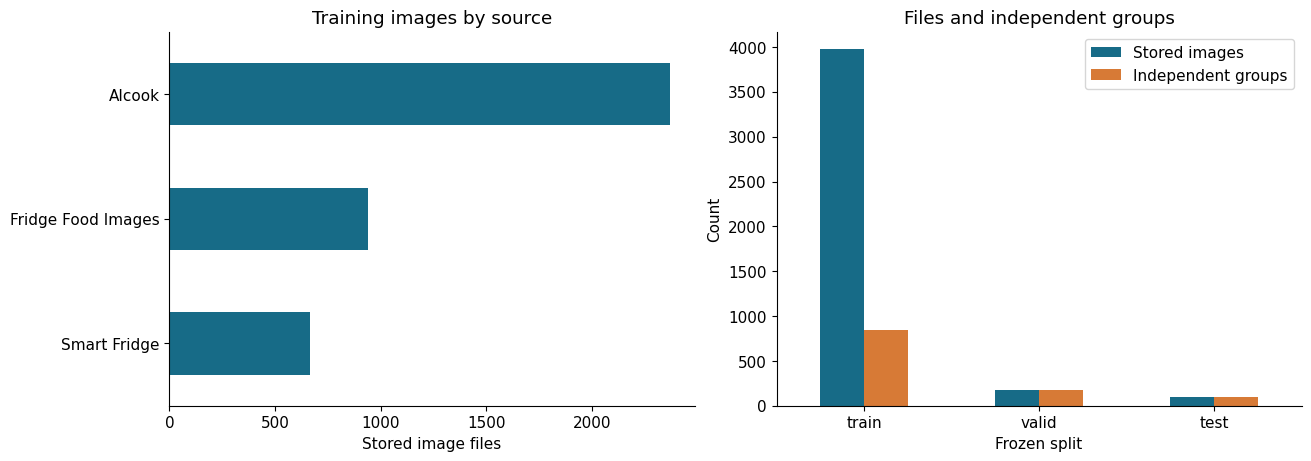

Training contains **3,972 files**, but **841 independent dependency groups**, **1,379 source photographs** and **1,323 scenes**. Related variants explain why file count is larger. **AIcook** contributes **59.6%** of training files, so the dataset is not evenly balanced across sources.

In [ ]:
eda_source_counts = eda_images.pivot_table(index="dataset_name", columns="split", values="image_id",
    aggfunc="size", fill_value=0).reindex(columns=eda_split_order)
eda_source_counts["total"] = eda_source_counts.sum(axis=1)
eda_display(eda_source_counts)
with eda_plot.rc_context({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False}):
    eda_figure, eda_axes = eda_plot.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
    eda_source_counts["train"].sort_values().plot.barh(ax=eda_axes[0], color=eda_colours["train"])
    eda_axes[0].set(title="Training images by source", xlabel="Stored image files", ylabel="")
    eda_split_summary[["images", "independent_groups"]].plot.bar(ax=eda_axes[1], color=["#176B87", "#D77A36"], rot=0)
    eda_axes[1].set(title="Files and independent groups", xlabel="Frozen split", ylabel="Count")
    eda_axes[1].legend(["Stored images", "Independent groups"])
    eda_plot.show()
    eda_plot.close(eda_figure)
eda_train_images = eda_images[eda_images.split == "train"].copy()
eda_train_boxes = eda_boxes[eda_boxes.split == "train"].copy()
eda_largest_source = eda_source_counts["train"].idxmax()
eda_display(EdaMarkdown(
    f"Training contains **{len(eda_train_images):,} files**, but **{eda_train_images.split_dependency_id.nunique():,} "
    f"independent dependency groups**, **{eda_train_images.source_photograph_id.nunique():,} source photographs** and "
    f"**{eda_train_images.scene_id.nunique():,} scenes**. Related variants explain why file count is larger. "
    f"**{eda_largest_source}** contributes **{100 * eda_source_counts.loc[eda_largest_source, 'train'] / len(eda_train_images):.1f}%** "
    "of training files, so the dataset is not evenly balanced across sources."))

### 3. Class balance
Count boxes, images and independent groups for each ingredient. One image can contain several classes. The chart shows all 42 classes and their validation support; results for rarely represented classes are less reliable.

In [ ]:
# Link each box to its image group before counting class support.
eda_boxes_with_groups = eda_boxes.merge(eda_images[["image_id", "split_dependency_id"]], on="image_id", validate="many_to_one")
eda_support_parts = []
for eda_split in eda_split_order:
    eda_selected_boxes = eda_boxes_with_groups[eda_boxes_with_groups.split == eda_split]
    eda_calculated = eda_selected_boxes.groupby("class_id").agg(
        objects=("image_id", "size"), images=("image_id", "nunique"), independent_groups=("split_dependency_id", "nunique"))
    eda_calculated = eda_calculated.reindex(sorted(eda_class_names), fill_value=0).reset_index()
    eda_calculated["split"] = eda_split
    eda_support_parts.append(eda_calculated)
eda_support = eda_pandas.concat(eda_support_parts, ignore_index=True)
eda_support_check = eda_support.merge(eda_frozen_support[eda_frozen_support.split.isin(eda_split_order)],
    left_on=["class_id", "split"], right_on=["export_class_id", "split"], suffixes=("_actual", "_metadata"), validate="one_to_one")
assert len(eda_support_check) == len(eda_class_names) * len(eda_split_order)
assert (eda_support_check.class_name == eda_support_check.class_id.map(eda_class_names)).all()
assert (eda_support_check.objects_actual == eda_support_check.objects_metadata).all()
assert (eda_support_check.images_actual == eda_support_check.images_metadata).all()
assert (eda_support_check.independent_groups == eda_support_check.independent_dependency_groups).all()
eda_class_table = eda_pandas.DataFrame({"class_id": sorted(eda_class_names),
    "class_name": [eda_class_names[index] for index in sorted(eda_class_names)]})
for eda_split, eda_prefix in [("train", "train"), ("valid", "validation")]:
    eda_part = eda_support[eda_support.split == eda_split].drop(columns="split")
    eda_part = eda_part.rename(columns={name: eda_prefix + "_" + name for name in ["objects", "images", "independent_groups"]})
    eda_class_table = eda_class_table.merge(eda_part, on="class_id", validate="one_to_one")
with eda_pandas.option_context("display.max_rows", 50, "display.max_columns", 10):
    eda_display(eda_class_table)
print("All", len(eda_support_check), "split/class support rows agree with frozen metadata.")

,class_id,class_name,train_objects,train_images,train_independent_groups,validation_objects,validation_images,validation_independent_groups
0,0,apple,2230,1286,166,75,57,57
1,1,banana,1389,1303,187,50,50,50
2,2,beef,681,681,94,22,22,22
3,3,blueberries,927,927,142,27,27,27
4,4,bread,1733,1219,149,55,55,55
5,5,butter_or_spread,1548,1459,186,29,29,29
6,6,carrot,1708,1530,237,70,53,53
7,7,cheese,1478,1455,215,46,46,46
8,8,chicken,1039,1039,153,23,23,23
9,9,chicken_breast,585,585,77,32,32,32


All 126 split/class support rows agree with frozen metadata.


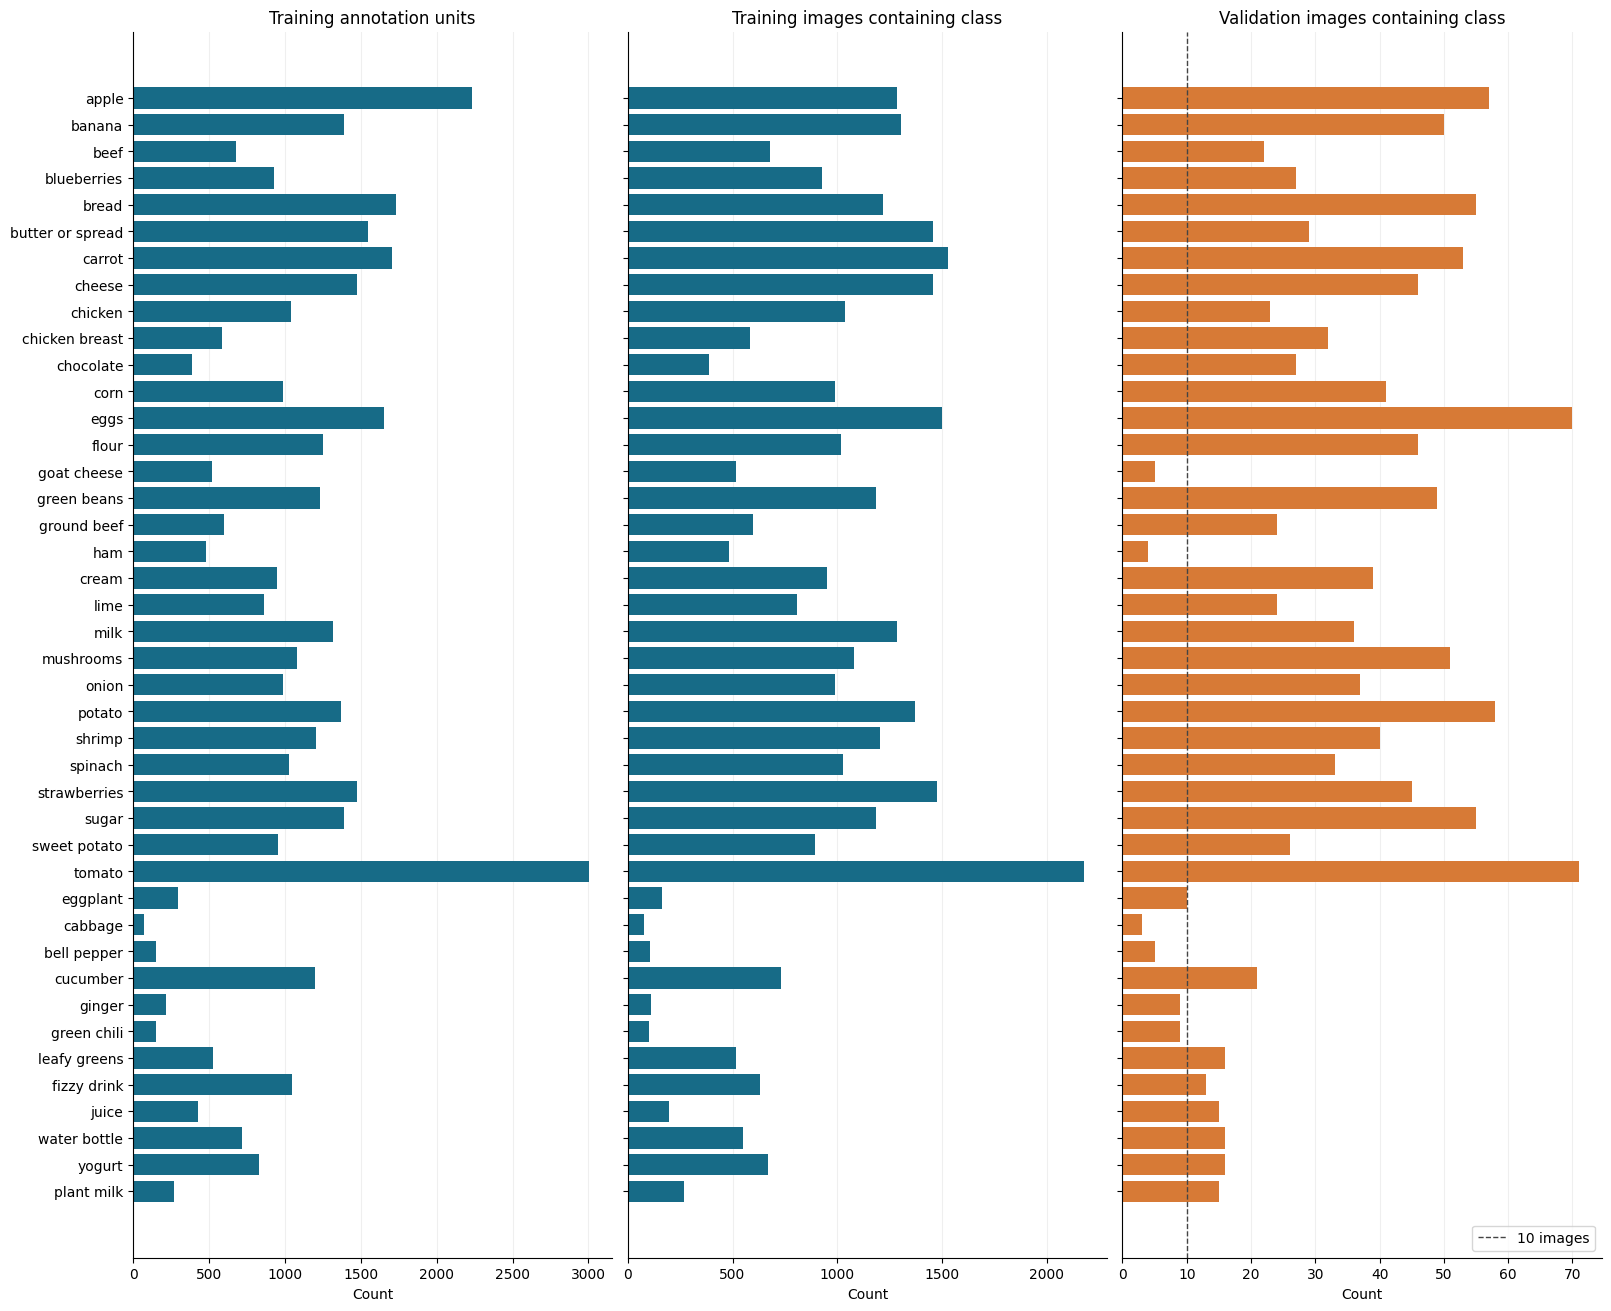

,class_name,train_images,train_independent_groups,validation_images,validation_objects
31,cabbage,75,30,3,3
17,ham,481,71,4,4
14,goat_cheese,517,82,5,5
32,bell_pepper,107,46,5,8
34,ginger,113,58,9,14
35,green_chili,100,50,9,14


**tomato** has **3,007** training boxes, while **cabbage** has **75** — a **40.1:1** frequency ratio. **6 classes** have fewer than ten validation images. Interpret their per-class scores with their support counts; neither rare classes nor their annotations were removed.

In [ ]:
with eda_plot.rc_context({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False}):
    eda_figure, eda_axes = eda_plot.subplots(1, 3, figsize=(16, 13), sharey=True, layout="constrained")
    eda_positions = eda_numpy.arange(len(eda_class_table))
    for eda_axis, eda_column, eda_title, eda_colour in zip(eda_axes,
        ["train_objects", "train_images", "validation_images"],
        ["Training annotation units", "Training images containing class", "Validation images containing class"],
        ["#176B87", "#176B87", "#D77A36"]):
        eda_axis.barh(eda_positions, eda_class_table[eda_column], color=eda_colour)
        eda_axis.set(title=eda_title, xlabel="Count", xlim=(0, None))
        eda_axis.grid(axis="x", alpha=0.2)
        eda_axis.set_axisbelow(True)
    eda_axes[0].set_yticks(eda_positions, eda_class_table.class_name.str.replace("_", " "))
    eda_axes[0].invert_yaxis()
    eda_axes[2].axvline(10, color="#444444", linestyle="--", linewidth=1, label="10 images")
    eda_axes[2].legend(loc="lower right")
    eda_plot.show()
    eda_plot.close(eda_figure)
eda_most_common = eda_class_table.loc[eda_class_table.train_objects.idxmax()]
eda_least_common = eda_class_table.loc[eda_class_table.train_objects.idxmin()]
eda_sparse_classes = eda_class_table[eda_class_table.validation_images < 10].sort_values("validation_images")
eda_display(eda_sparse_classes[["class_name", "train_images", "train_independent_groups", "validation_images", "validation_objects"]])
eda_display(EdaMarkdown(
    f"**{eda_most_common.class_name.replace('_', ' ')}** has **{int(eda_most_common.train_objects):,}** training boxes, "
    f"while **{eda_least_common.class_name.replace('_', ' ')}** has **{int(eda_least_common.train_objects):,}** "
    f"— a **{eda_most_common.train_objects / eda_least_common.train_objects:.1f}:1** frequency ratio. "
    f"**{len(eda_sparse_classes)} classes** have fewer than ten validation images. "
    "Interpret their per-class scores with their support counts; neither rare classes nor their annotations were removed."))

### 4. Image and box shapes
**Aspect ratio** is width divided by height. **Normalized box area** is the fraction of the image covered by a box.

These plots use training data and include negative images when counting objects per image. Small boxes are retained.

In [ ]:
# Read training-image sizes for the geometry plots.
eda_dimension_rows = []
for eda_row in eda_train_images.itertuples():
    with EdaImage.open(eda_dataset_root / eda_row.image_path) as eda_image:
        eda_width, eda_height = eda_image.size
    eda_dimension_rows.append({"image_id": eda_row.image_id, "width_px": eda_width, "height_px": eda_height,
                               "image_aspect_ratio": eda_width / eda_height})
eda_dimensions = eda_pandas.DataFrame(eda_dimension_rows)
eda_train_images = eda_train_images.merge(eda_dimensions, on="image_id", validate="one_to_one")
eda_geometry = eda_train_boxes.merge(eda_dimensions, on="image_id", validate="many_to_one")
eda_geometry["box_width_px"] = eda_geometry.box_width * eda_geometry.width_px
eda_geometry["box_height_px"] = eda_geometry.box_height * eda_geometry.height_px
eda_geometry["normalized_area"] = eda_geometry.box_width * eda_geometry.box_height
eda_geometry["box_aspect_ratio"] = eda_geometry.box_width_px / eda_geometry.box_height_px
eda_display(eda_train_images[["width_px", "height_px", "image_aspect_ratio", "objects"]].describe().round(3))
eda_display(eda_geometry[["box_width_px", "box_height_px", "normalized_area", "box_aspect_ratio"]].describe(
    percentiles=[0.05, 0.5, 0.95]).round(4))

,width_px,height_px,image_aspect_ratio,objects
count,3972.0,3972.0,3972.0,3972.000
mean,640.0,640.0,1.0,10.563
std,0.0,0.0,0.0,5.904
min,640.0,640.0,1.0,0.000
25%,640.0,640.0,1.0,9.000
50%,640.0,640.0,1.0,12.000
75%,640.0,640.0,1.0,14.000
max,640.0,640.0,1.0,55.000


,box_width_px,box_height_px,normalized_area,box_aspect_ratio
count,41957.0000,41957.0000,41957.0000,41957.0000
mean,108.4021,66.6174,0.0220,2.0190
std,58.8810,54.5353,0.0548,1.2319
min,9.0000,4.0943,0.0009,0.1163
5%,48.0000,27.5000,0.0047,0.6042
50%,98.0000,54.0000,0.0137,1.8116
95%,186.0000,136.5000,0.0403,4.1781
max,640.0000,640.0000,1.0000,39.2251


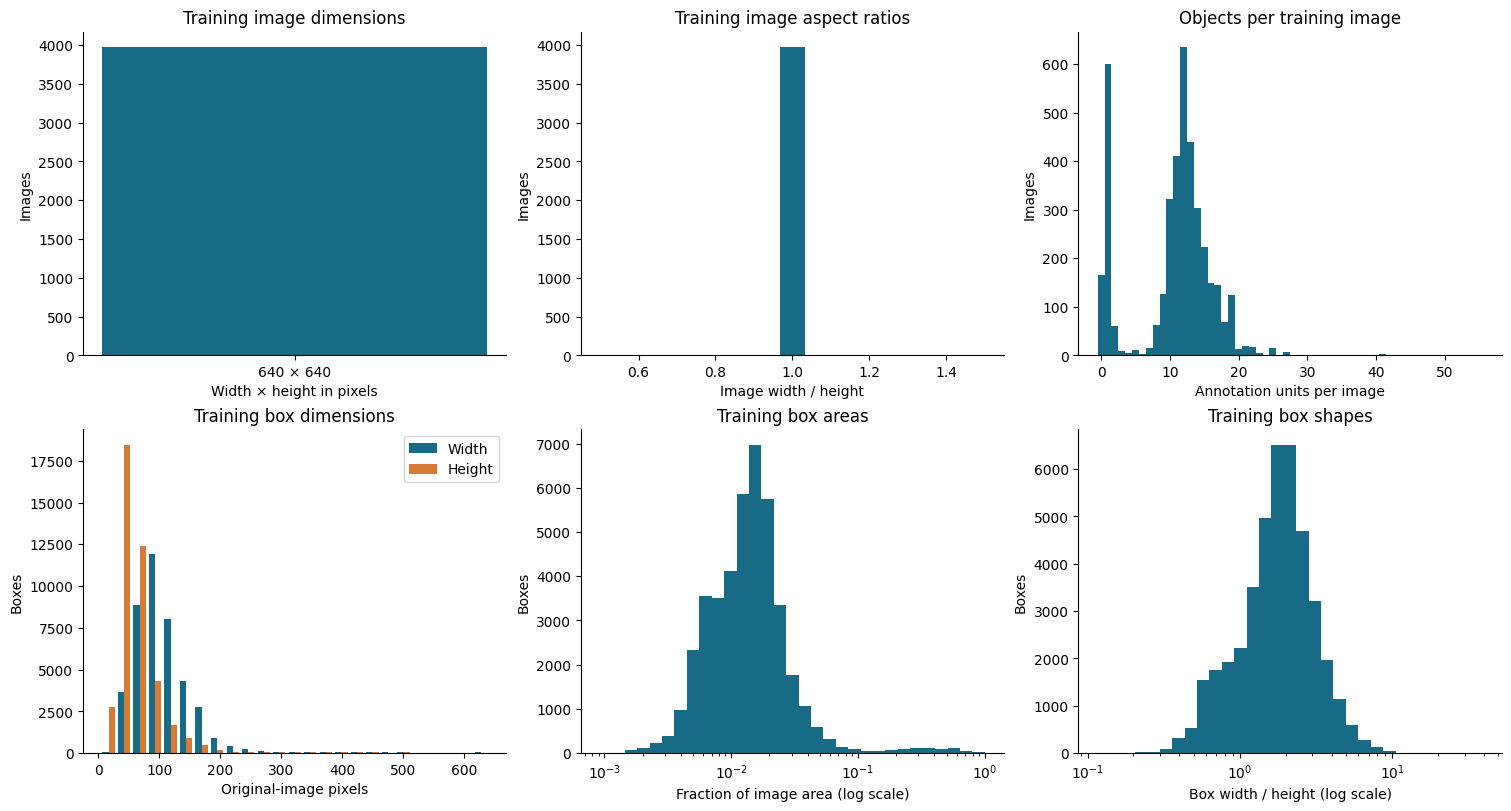

Training has **1 stored image dimension combination(s)**. The median image contains **12 boxes**, and the most crowded contains **55**. The median box occupies **1.37%** of its image; **31.9%** of boxes occupy less than 1%. This suggests scale and clutter are relevant detection challenges. Stored dimensions reflect the exported images, not necessarily the original camera resolution.

In [ ]:
with eda_plot.rc_context({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False}):
    eda_figure, eda_axes = eda_plot.subplots(2, 3, figsize=(15, 8), layout="constrained")
    eda_dimension_counts = eda_dimensions.groupby(["width_px", "height_px"]).size()
    eda_axes[0, 0].bar([f"{width} × {height}" for width, height in eda_dimension_counts.index], eda_dimension_counts, color="#176B87")
    eda_axes[0, 0].set(title="Training image dimensions", xlabel="Width × height in pixels", ylabel="Images")
    eda_axes[0, 1].hist(eda_train_images.image_aspect_ratio, bins=15, color="#176B87")
    eda_axes[0, 1].set(title="Training image aspect ratios", xlabel="Image width / height", ylabel="Images")
    eda_axes[0, 2].hist(eda_train_images.objects, bins=eda_numpy.arange(eda_train_images.objects.max() + 2) - 0.5, color="#176B87")
    eda_axes[0, 2].set(title="Objects per training image", xlabel="Annotation units per image", ylabel="Images")
    eda_axes[1, 0].hist([eda_geometry.box_width_px, eda_geometry.box_height_px], bins=25,
        label=["Width", "Height"], color=["#176B87", "#D77A36"])
    eda_axes[1, 0].set(title="Training box dimensions", xlabel="Original-image pixels", ylabel="Boxes")
    eda_axes[1, 0].legend()
    eda_axes[1, 1].hist(eda_geometry.normalized_area, bins=eda_numpy.geomspace(eda_geometry.normalized_area.min(),
        eda_geometry.normalized_area.max(), 32), color="#176B87")
    eda_axes[1, 1].set(xscale="log", title="Training box areas", xlabel="Fraction of image area (log scale)", ylabel="Boxes")
    eda_axes[1, 2].hist(eda_geometry.box_aspect_ratio, bins=eda_numpy.geomspace(eda_geometry.box_aspect_ratio.min(),
        eda_geometry.box_aspect_ratio.max(), 32), color="#176B87")
    eda_axes[1, 2].set(xscale="log", title="Training box shapes", xlabel="Box width / height (log scale)", ylabel="Boxes")
    eda_plot.show()
    eda_plot.close(eda_figure)
eda_small_share = 100 * eda_geometry.normalized_area.lt(0.01).mean()
eda_display(EdaMarkdown(
    f"Training has **{len(eda_dimension_counts)} stored image dimension combination(s)**. "
    f"The median image contains **{eda_train_images.objects.median():.0f} boxes**, and the most crowded contains "
    f"**{eda_train_images.objects.max():.0f}**. The median box occupies **{100 * eda_geometry.normalized_area.median():.2f}%** "
    f"of its image; **{eda_small_share:.1f}%** of boxes occupy less than 1%. "
    "This suggests scale and clutter are relevant detection challenges. Stored dimensions reflect the exported images, not necessarily the original camera resolution."))

### 5. Box shapes
The scatter plot shows normalized width and height for a fixed sample of up to 3,000 training boxes. Sampling changes only this plot.

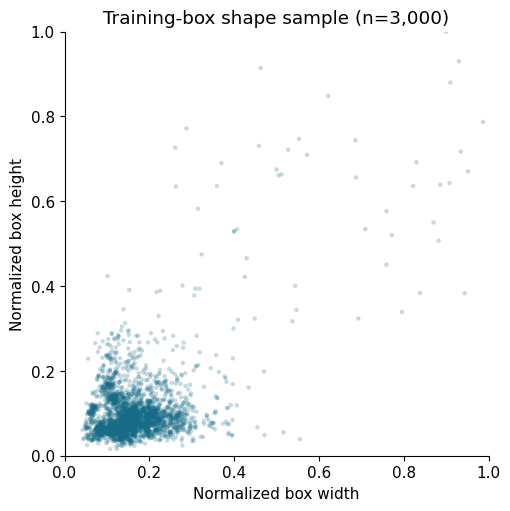

In [ ]:
# Use a fixed sample to keep the shape plot repeatable.
eda_scatter_sample = eda_train_boxes.sample(n=min(3000, len(eda_train_boxes)), random_state=EDA_SAMPLE_SEED)
with eda_plot.rc_context({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False}):
    eda_figure, eda_axis = eda_plot.subplots(figsize=(6, 5), layout="constrained")
    eda_axis.scatter(eda_scatter_sample.box_width, eda_scatter_sample.box_height,
        s=10, alpha=0.25, color="#176B87", edgecolors="none")
    eda_axis.set(title=f"Training-box shape sample (n={len(eda_scatter_sample):,})",
        xlabel="Normalized box width", ylabel="Normalized box height", xlim=(0, 1), ylim=(0, 1), aspect="equal")
    eda_plot.show()
    eda_plot.close(eda_figure)


### 6. Labelled training examples
Show one positive image from each source, a crowded image and a reviewed negative. Numbered boxes match the labels below each image. These are dataset annotations, not predictions. A negative may contain unsupported foods.

,image_id,dataset_name,objects,reviewed_negative,split_dependency_id
193,ai__13f7cf9dc0d9d8442a5a,AIcook,10,False,SPLIT_d59ea86e21773b4d
2599,ffi__42275411462c1320544b,Fridge Food Images,1,False,SPLIT_4503fdbb4180959f
3310,smart__017b9759ee67c536f3e5,Smart Fridge,13,False,SPLIT_f6a277f2eb7ac06d
2654,ffi__505d978b17b98a854621,Fridge Food Images,55,False,SPLIT_5d2d13dc2749ef29
2511,ffi__2560e39afd3aea4748f3,Fridge Food Images,0,True,SPLIT_bb2f6ecc1107fadd


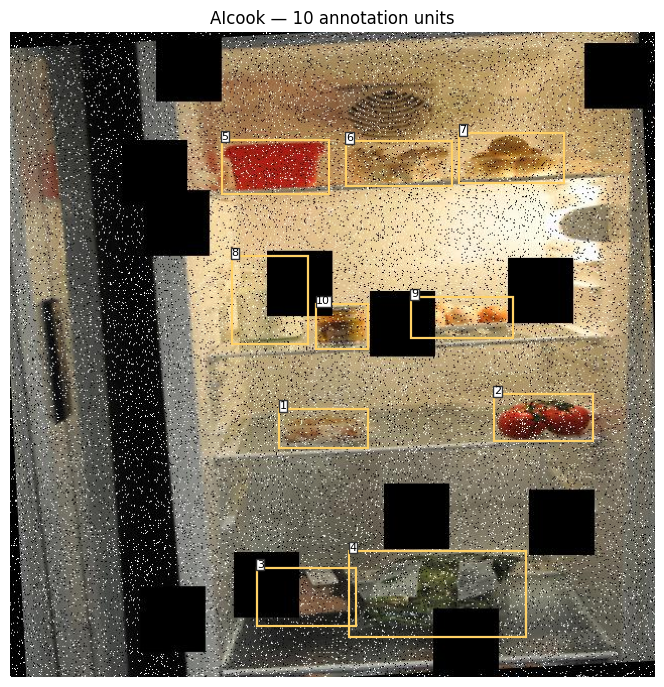

**Image:** ai__13f7cf9dc0d9d8442a5a  
**Box labels:** 1: shrimp; 2: tomato; 3: chicken breast; 4: spinach; 5: butter or spread; 6: mushrooms; 7: sweet potato; 8: sugar; 9: eggs; 10: corn

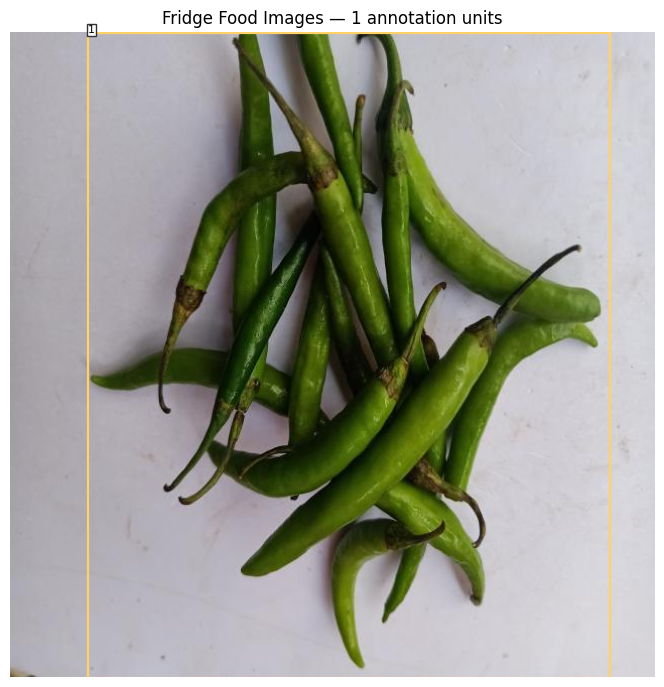

**Image:** ffi__42275411462c1320544b  
**Box labels:** 1: green chili

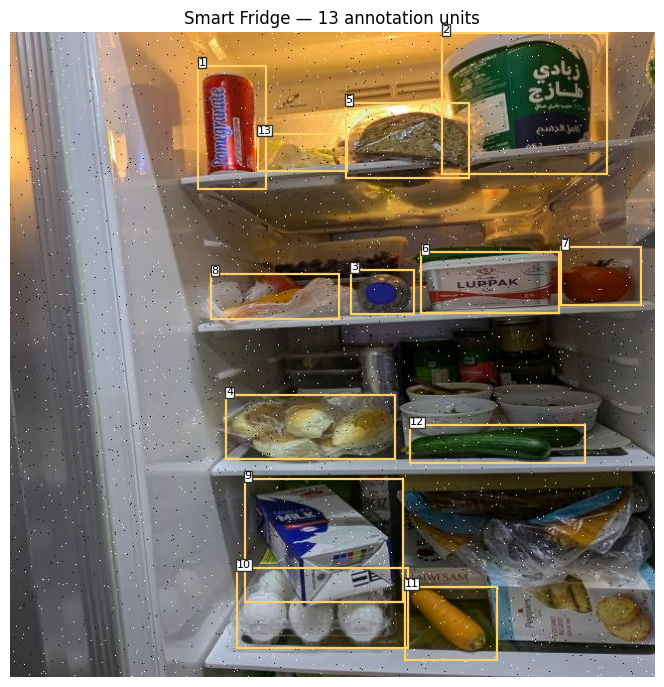

**Image:** smart__017b9759ee67c536f3e5  
**Box labels:** 1: fizzy drink; 2: yogurt; 3: water bottle; 4: bread; 5: bread; 6: butter or spread; 7: tomato; 8: carrot; 9: milk; 10: eggs; 11: carrot; 12: cucumber; 13: leafy greens

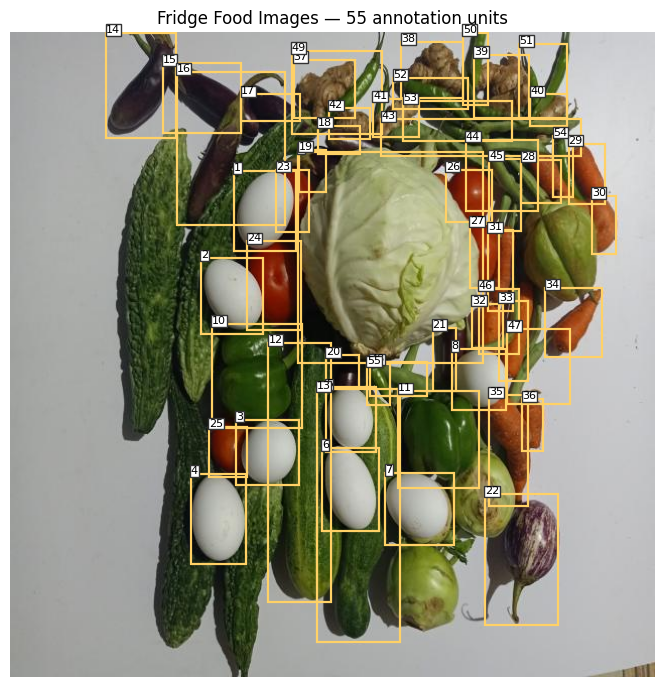

**Image:** ffi__505d978b17b98a854621  
**Box labels:** 1: eggs; 2: eggs; 3: eggs; 4: eggs; 5: eggs; 6: eggs; 7: eggs; 8: eggs; 9: cabbage; 10: bell pepper; 11: bell pepper; 12: cucumber; 13: cucumber; 14: eggplant; 15: eggplant; 16: eggplant; 17: eggplant; 18: eggplant; 19: eggplant; 20: eggplant; 21: eggplant; 22: eggplant; 23: tomato; 24: tomato; 25: tomato; 26: tomato; 27: tomato; 28: carrot; 29: carrot; 30: carrot; 31: carrot; 32: carrot; 33: carrot; 34: carrot; 35: carrot; 36: carrot; 37: ginger; 38: ginger; 39: ginger; 40: ginger; 41: ginger; 42: ginger; 43: green beans; 44: green beans; 45: green beans; 46: green beans; 47: green beans; 48: green beans; 49: green chili; 50: green chili; 51: green chili; 52: green chili; 53: green chili; 54: green chili; 55: green chili

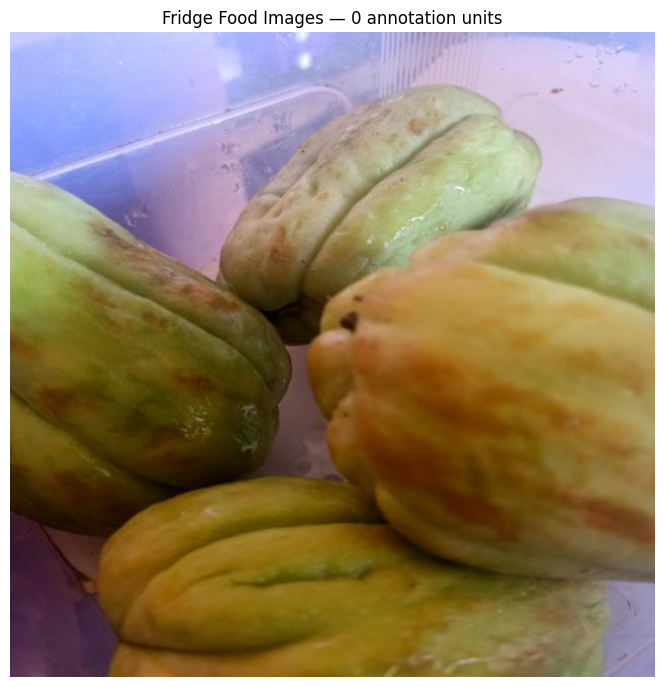

**Image:** ffi__2560e39afd3aea4748f3  
**Reviewed negative:** no supported-scope boxes.

In [ ]:
# Include source examples, a crowded scene and a negative image.
eda_sample_indices = []
for eda_source, eda_source_rows in eda_train_images[eda_train_images.objects > 0].groupby("dataset_name", sort=True):
    eda_representatives = eda_source_rows.sort_values("image_id").drop_duplicates("split_dependency_id")
    eda_sample_indices.append(eda_representatives.sample(1, random_state=EDA_SAMPLE_SEED).index[0])
eda_sample_indices.append(eda_train_images.sort_values(["objects", "image_id"], ascending=[False, True]).index[0])
eda_negative_pool = eda_train_images[eda_train_images.reviewed_negative].sort_values("image_id")
if not eda_negative_pool.empty:
    eda_sample_indices.append(eda_negative_pool.sample(1, random_state=EDA_SAMPLE_SEED).index[0])
eda_sample = eda_train_images.loc[list(dict.fromkeys(eda_sample_indices))]
eda_display(eda_sample[["image_id", "dataset_name", "objects", "reviewed_negative", "split_dependency_id"]])


def eda_show_training_annotations(row):
    """Display one selected training photograph with its original boxes and a numbered ingredient key."""
    assert row.split == "train"
    with EdaImage.open(eda_dataset_root / row.image_path) as opened_image:
        photograph = opened_image.convert("RGB")
    annotations = eda_train_boxes[eda_train_boxes.image_id == row.image_id]
    with eda_plot.rc_context({"font.size": 11}):
        figure, axis = eda_plot.subplots(figsize=(7, 7))
        axis.imshow(photograph)
        key = []
        for number, box in enumerate(annotations.itertuples(), 1):
            left = (box.center_x - box.box_width / 2) * photograph.width
            top = (box.center_y - box.box_height / 2) * photograph.height
            axis.add_patch(EdaRectangle((left, top), box.box_width * photograph.width,
                box.box_height * photograph.height, fill=False, edgecolor="#FFD166", linewidth=1.6))
            axis.text(left, top, str(number), fontsize=8, color="black",
                bbox={"facecolor": "white", "edgecolor": "#333333", "pad": 0.5})
            key.append(f"{number}: {eda_class_names[box.class_id].replace('_', ' ')}")
        axis.set_title(f"{row.dataset_name} — {int(row.objects)} annotation units", fontsize=12)
        axis.axis("off")
        eda_plot.tight_layout()
        eda_plot.show()
        eda_plot.close(figure)
    eda_display(EdaMarkdown("**Image:** " + row.image_id + "  \n" +
        ("**Box labels:** " + "; ".join(key) if key else "**Reviewed negative:** no supported-scope boxes.")))


for eda_sample_row in eda_sample.itertuples():
    eda_show_training_annotations(eda_sample_row)

### EDA findings
The summary below reports calculated dataset properties. It does not measure model accuracy.

In [ ]:
eda_sparse_description = ", ".join(
    f"{row.class_name.replace('_', ' ')} ({int(row.validation_images)} images)" for row in eda_sparse_classes.itertuples())
eda_display(EdaMarkdown(
    f"- **Size:** {len(eda_images):,} images and {len(eda_boxes):,} annotation units across {len(eda_class_names)} classes.\n"
    f"- **Negatives:** {int(eda_images.reviewed_negative.sum())} reviewed negative images; missing annotation files are reported separately and total zero.\n"
    f"- **Independent evidence:** the {len(eda_train_images):,} training files represent {eda_train_images.split_dependency_id.nunique():,} dependency groups. Related augmented variants should not be counted as independent photographs.\n"
    f"- **Imbalance:** the largest-to-smallest training box-frequency ratio is {eda_most_common.train_objects / eda_least_common.train_objects:.1f}:1. Overall model metrics can hide weaker classes.\n"
    f"- **Sparse validation support:** {eda_sparse_description}. Per-class metrics need these denominators.\n"
    f"- **Scale and clutter:** {eda_small_share:.1f}% of training boxes occupy less than 1% of image area; the most crowded image has {int(eda_train_images.objects.max())} boxes.\n"
    "- **Scope:** package and batch annotations do not measure food quantity, freshness or expiry.\n"
    "- **Sources:** calculations reconcile with the dataset README, export registry, class-split support CSV and image-provenance CSV. The completed preparation review is reused; it is not repeated here."))

- **Size:** 4,243 images and 44,348 annotation units across 42 classes.
- **Negatives:** 195 reviewed negative images; missing annotation files are reported separately and total zero.
- **Independent evidence:** the 3,972 training files represent 841 dependency groups. Related augmented variants should not be counted as independent photographs.
- **Imbalance:** the largest-to-smallest training box-frequency ratio is 40.1:1. Overall model metrics can hide weaker classes.
- **Sparse validation support:** cabbage (3 images), ham (4 images), goat cheese (5 images), bell pepper (5 images), ginger (9 images), green chili (9 images). Per-class metrics need these denominators.
- **Scale and clutter:** 31.9% of training boxes occupy less than 1% of image area; the most crowded image has 55 boxes.
- **Scope:** package and batch annotations do not measure food quantity, freshness or expiry.
- **Sources:** calculations reconcile with the dataset README, export registry, class-split support CSV and image-provenance CSV. The completed preparation review is reused; it is not repeated here.

In [ ]:
CLASS_NAMES = [eda_class_names[index] for index in sorted(eda_class_names)]

# Check content against the frozen export, including the empty annotation files.
identity_rows = []
for row in eda_provenance.itertuples():
    image_hash = sha256_file(DATASET_ROOT / row.image_path)
    label_hash = sha256_file(DATASET_ROOT / row.label_path)
    assert image_hash == row.source_file_sha256 and label_hash == row.label_sha256, row.source_image_id
    identity_rows.append([row.image_path, image_hash, row.label_path, label_hash])
identity_payload = {"files": sorted(identity_rows), "classes": CLASS_NAMES,
                    "provenance_sha256": sha256_file(DATASET_ROOT / "metadata/image_provenance.csv")}
DATASET_ID = hashlib.sha256(json.dumps(identity_payload, sort_keys=True).encode()).hexdigest()
save_json(EVAL_DIR / "dataset_identity.json", {"sha256": DATASET_ID, "class_names": CLASS_NAMES,
    "images": len(eda_images), "objects": len(eda_boxes), "file_hashes_checked": True,
    "splits": eda_split_summary.reset_index().to_dict("records")})
print("Verified dataset fingerprint:", DATASET_ID)

Verified dataset fingerprint: 2d8f5b1d51a717270f3c9c45038cba758a1fd69764a48cc3dff161677132c03c


## Training limits and progress
Full training starts from pretrained RF-DETR Small weights after a small compatibility check. Smoke-check scores are not final accuracy.

Training stops at 20 epochs, or after four validation checks without a mAP50–95 improvement of at least 0.001. A 50-minute timer requests a stop; a separate supervisor enforces the 60-minute training-cell budget. Fewer than 20 epochs may finish.

Training is optional. To repeat it, set `mode="full-training"`, `full_checkpoint=None`, `run_validation=True`, `final_test_enabled=False` and `settings_frozen=False`. New training starts from pretrained weights and evaluates its own new checkpoint.

Use `smoke-check` for compatibility only. Resume needs a full `.ckpt` from a new training run, plus its metadata and remaining time budget. The submission contains inference weights only; its completed run cannot be resumed from `.pth`.

In [ ]:
from pytorch_lightning import Callback, seed_everything
from pytorch_lightning.callbacks import Timer
from rfdetr import RFDETR
from rfdetr.config import RFDETRSmallConfig, TrainConfig
from rfdetr.training import RFDETRDataModule, RFDETRModelModule, build_trainer


def build_native_configs(job, dataset_dir, output_dir, smoke=False):
    """Build model and training settings from a job record without constructing a model."""
    settings = job["config"]
    model_config = RFDETRSmallConfig(
        num_classes=len(job["class_names"]), device="cuda",
        resolution=settings["image_size"], num_select=settings["max_detections"],
        compile=False, gradient_checkpointing=False,
    )
    # Use one epoch for compatibility and the configured limit for training.
    train_config = TrainConfig(
        dataset_dir=str(dataset_dir), dataset_file="yolo", output_dir=str(output_dir),
        class_names=job["class_names"], epochs=1 if smoke else settings["epochs"],
        batch_size=settings["batch"], eval_batch_size=settings["batch"],
        grad_accum_steps=1 if smoke else settings["grad_accum_steps"],
        lr=settings["lr"], lr_encoder=settings["lr_encoder"],
        warmup_epochs=0.0 if smoke else 1.0,
        lr_scheduler="cosine", lr_scheduler_kwargs={"min_factor": 0.1},
        weight_decay=1e-4, amp_dtype="fp16", accelerator="gpu", devices=1,
        num_workers=settings["num_workers"],
        multi_scale=False, expanded_scales=False, scale_jitter=False,
        augmentation_backend="torchvision", aug_config=None,
        use_ema=False, eval_base_model=True,
        early_stopping=not smoke, early_stopping_patience=settings["patience"],
        early_stopping_min_delta=settings["min_delta"], best_model_metric="map",
        checkpoint_interval=5, eval_interval=1,
        eval_max_dets=settings["max_detections"], log_per_class_metrics=True,
        compute_val_loss=True, num_sanity_val_steps=0, save_dataset_grids=False,
        tensorboard=False, wandb=False, mlflow=False, progress_bar="tqdm", run_test=False,
    )
    return model_config, train_config


class NotebookProgress(Callback):
    """Publish compact progress records for the notebook without touching model weights."""
    def __init__(self, job, stage):
        self.job, self.stage, self.previous_write = job, stage, 0.0
        self.observed_training_device = None

    def publish(self, trainer, phase, batch=0, batches=0, force=False):
        now = time.time()
        if not force and now - self.previous_write < 2:
            return
        self.previous_write = now
        stopping = next((item for item in trainer.callbacks
                         if item.__class__.__name__ == "RFDETREarlyStopping"), None)
        metrics = {key: float(value.detach().cpu()) for key, value in trainer.callback_metrics.items()
                   if isinstance(value, torch.Tensor) and value.numel() == 1
                   and key in {"train/loss", "val/loss", "val/mAP_50", "val/mAP_50_95"}}
        save_json(Path(self.job["status_path"]), {
            "stage": self.stage, "phase": phase, "epoch": trainer.current_epoch + 1,
            "maximum_epochs": trainer.max_epochs, "batch": batch, "batches": batches,
            "optimizer_updates": trainer.global_step, "metrics": metrics,
            "patience_used": int(stopping.wait_count) if stopping else 0,
            "elapsed_seconds": self.job["previous_seconds"] + time.monotonic() - self.job["launched_monotonic"],
        })

    def on_train_batch_end(self, trainer, pl_module, outputs, batch, batch_idx):
        # Observe the device during training because Lightning moves weights to CPU during cleanup.
        self.observed_training_device = str(next(pl_module.parameters()).device)
        assert self.observed_training_device.startswith("cuda"), "A training batch did not execute on CUDA."
        self.publish(trainer, "training", batch_idx + 1, int(trainer.num_training_batches))

    def on_validation_batch_end(self, trainer, pl_module, outputs, batch, batch_idx, dataloader_idx=0):
        self.publish(trainer, "validation", batch_idx + 1, int(trainer.num_val_batches[0]))

    def on_train_epoch_end(self, trainer, pl_module):
        self.publish(trainer, "epoch completed", force=True)


### Training augmentation
**Augmentation** makes temporary training variations. This setup uses a horizontal flip with 50% probability, a fixed 512 × 512 resize and channel normalization. Extra colour changes, cropping and mixing are disabled.

The previews use the actual training transforms, with fixed seeds chosen to show a flip. Checks confirm the boxes remain valid. Validation uses fixed preprocessing. No extra image files are added.

/usr/local/lib/python3.13/dist-packages/rfdetr/datasets/yolo.py:1104: UserWarning: RF-DETR has changed the default training augmentation backend from Albumentations (cv2 INTER_LINEAR, no antialias) to torchvision (BILINEAR + antialias=True). Pixel values will differ slightly from previous versions; mAP may drift on existing benchmarks. To restore the previous behaviour, install rfdetr[augment] and pass aug_config=AUG_CONFIG from rfdetr.datasets.aug_configs.
  transforms=make_coco_transforms_square_div_64(


creating index...
index created!
creating index...
index created!
Actual training pipeline: {
  "name": "Compose",
  "steps": [
    {
      "name": "RandomChoice",
      "steps": [
        {
          "name": "Resize",
          "size": [
            512,
            512
          ]
        }
      ]
    },
    {
      "name": "RandomHorizontalFlip",
      "p": 0.5
    },
    {
      "name": "ToImage"
    },
    {
      "name": "ToDtype"
    },
    {
      "name": "Normalize",
      "channel_normalization": {
        "name": "Normalize",
        "mean": [
          0.485,
          0.456,
          0.406
        ],
        "std": [
          0.229,
          0.224,
          0.225
        ]
      }
    }
  ]
}
Actual validation pipeline: {
  "name": "Compose",
  "steps": [
    {
      "name": "Resize",
      "size": [
        512,
        512
      ]
    },
    {
      "name": "ToImage"
    },
    {
      "name": "ToDtype"
    },
    {
      "name": "Normalize",
      "channel_normaliz

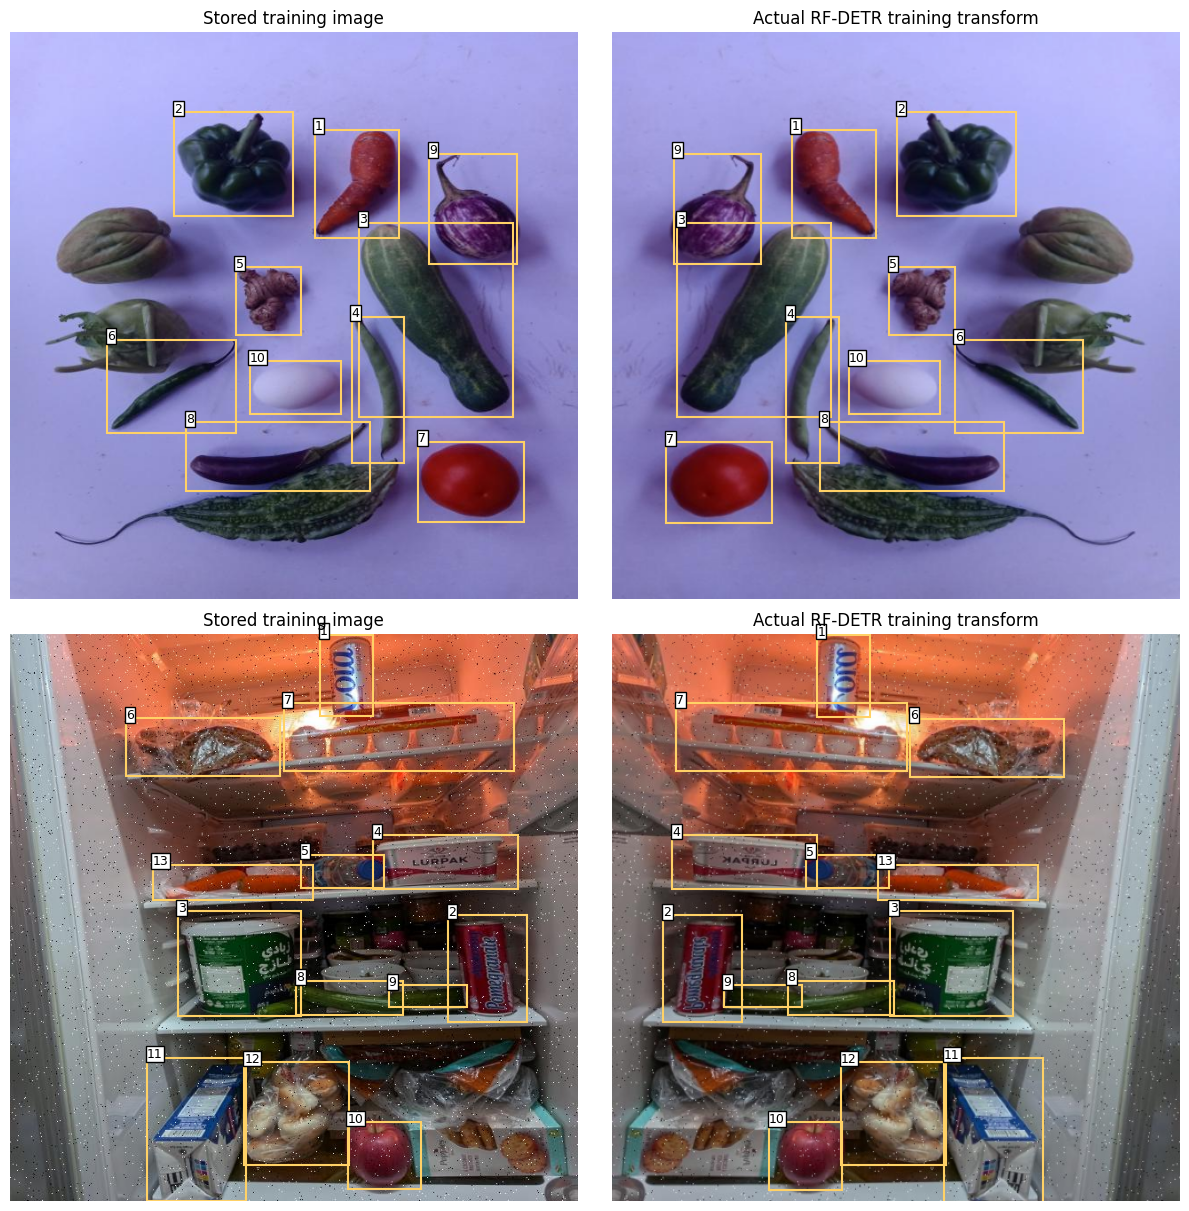

**ffi__c6a239808badbc619be9** — 1: carrot; 2: bell pepper; 3: cucumber; 4: green beans; 5: ginger; 6: green chili; 7: tomato; 8: eggplant; 9: eggplant; 10: eggs

**smart__73610a2a433450fd2adf** — 1: fizzy drink; 2: fizzy drink; 3: yogurt; 4: butter or spread; 5: water bottle; 6: bread; 7: eggs; 8: cucumber; 9: cucumber; 10: apple; 11: milk; 12: bread; 13: carrot

Native loader, sample boxes, labels and repeated validation preprocessing checks passed.


In [ ]:
# Preview the same transforms that the training loader uses.
preview_job = {"config": CONFIG, "class_names": CLASS_NAMES}
preview_model_config, preview_train_config = build_native_configs(preview_job, DATASET_ROOT, WORK_ROOT / "loader_preview")
preview_data = RFDETRDataModule(preview_model_config, preview_train_config)
preview_data.setup("fit")
assert preview_data.class_names == CLASS_NAMES
preview_dataset = preview_data._dataset_train
validation_dataset = preview_data._dataset_val
assert len(preview_dataset) == int(eda_split_summary.loc["train", "images"])
assert len(validation_dataset) == int(eda_split_summary.loc["valid", "images"])
def describe_transform(transform):
    """Describe each native transform and its parameters without relying on object memory addresses."""
    details = {"name": type(transform).__name__}
    for field in ["p", "size", "sizes", "max_size", "antialias", "interpolation", "mean", "std"]:
        if hasattr(transform, field):
            value = getattr(transform, field)
            details[field] = value if isinstance(value, (str, int, float, list, tuple, bool, type(None))) else str(value)
    if hasattr(transform, "transforms"):
        details["steps"] = [describe_transform(step) for step in transform.transforms]
    if hasattr(transform, "_normalize"):
        details["channel_normalization"] = describe_transform(transform._normalize)
    return details

training_pipeline = describe_transform(preview_dataset._transforms)
validation_pipeline = describe_transform(validation_dataset._transforms)
print("Actual training pipeline:", json.dumps(training_pipeline, indent=2))
print("Actual validation pipeline:", json.dumps(validation_pipeline, indent=2))
preview_candidates = eda_train_images[eda_train_images.objects.between(2, 15)].sort_values("image_id")
preview_choices = pd.concat([preview_candidates[preview_candidates.dataset_name == source].sample(
    1, random_state=CONFIG["seed"]) for source in ["Fridge Food Images", "Smart Fridge"]])
preview_paths = sorted(path for path in (DATASET_ROOT / "train/images").iterdir() if path.suffix.lower() in {".jpg", ".jpeg", ".png"})
preview_lookup = {path.stem: index for index, path in enumerate(preview_paths)}
preview_python_state = random.getstate()
preview_numpy_state = np.random.get_state()
preview_records = []
from matplotlib.patches import Rectangle
with torch.random.fork_rng(devices=[]):
    try:
        fig, axes = plt.subplots(2, 2, figsize=(12, 12), layout="constrained")
        for panel, row in enumerate(preview_choices.itertuples()):
            original_boxes = eda_train_boxes[eda_train_boxes.image_id == row.image_id]
            expected_boxes = original_boxes[["center_x", "center_y", "box_width", "box_height"]].to_numpy().copy()
            expected_boxes[:, 0] = 1 - expected_boxes[:, 0]
            # Select a reproducible seed that illustrates the active flip without changing its probability.
            for attempt in range(20):
                preview_seed = CONFIG["seed"] + panel * 20 + attempt
                random.seed(preview_seed)
                torch.manual_seed(preview_seed)
                tensor, target = preview_dataset[preview_lookup[row.image_id]]
                boxes = target["boxes"].cpu().numpy()
                labels = target["labels"].cpu().numpy()
                if boxes.shape == expected_boxes.shape and np.allclose(boxes, expected_boxes, atol=1e-5):
                    break
            else:
                raise AssertionError("No flipped sample found; inspect the active transform pipeline.")
            assert len(boxes) == len(original_boxes)
            assert sorted(labels.tolist()) == sorted(original_boxes.class_id.tolist())
            assert np.isfinite(boxes).all() and (boxes[:, 2:] > 0).all()
            assert (boxes[:, :2] - boxes[:, 2:] / 2 >= -1e-5).all()
            assert (boxes[:, :2] + boxes[:, 2:] / 2 <= 1 + 1e-5).all()
            pixels = tensor.permute(1, 2, 0).cpu().numpy()
            pixels = np.clip(pixels * np.array([.229, .224, .225]) + np.array([.485, .456, .406]), 0, 1)
            with Image.open(DATASET_ROOT / row.image_path) as source:
                original = np.asarray(source.convert("RGB"))
            original_coordinates = original_boxes[["center_x", "center_y", "box_width", "box_height"]].to_numpy()
            for axis, photograph, coordinates, names, title in [
                (axes[panel, 0], original, original_coordinates, original_boxes.class_id.to_numpy(), "Stored training image"),
                (axes[panel, 1], pixels, boxes, labels, "Actual RF-DETR training transform")]:
                height, width = photograph.shape[:2]
                axis.imshow(photograph)
                for number, (box, class_id) in enumerate(zip(coordinates, names), 1):
                    center_x, center_y, box_width, box_height = box
                    left, top = (center_x-box_width/2)*width, (center_y-box_height/2)*height
                    axis.add_patch(Rectangle((left, top), box_width*width, box_height*height,
                                             fill=False, edgecolor="#FFD166", linewidth=1.5))
                    axis.text(left, top, str(number), fontsize=9, color="black",
                              bbox={"facecolor":"white", "pad":1})
                axis.set_title(title)
                axis.axis("off")
            preview_records.append({"image_id": row.image_id, "targets_before": len(original_boxes),
                                    "targets_after": len(boxes), "preview_seed": preview_seed, "flip_geometry_verified": True, "labels": [CLASS_NAMES[int(i)] for i in labels]})
        plt.show()
        plt.close(fig)
    finally:
        random.setstate(preview_python_state)
        np.random.set_state(preview_numpy_state)
for item in preview_records:
    display(Markdown("**" + item["image_id"] + "** — " + "; ".join(
        f"{index}: {name.replace('_', ' ')}" for index, name in enumerate(item["labels"], 1))))
validation_first, validation_target = validation_dataset[0]
validation_again, validation_target_again = validation_dataset[0]
assert torch.equal(validation_first, validation_again)
assert torch.equal(validation_target["boxes"], validation_target_again["boxes"])
save_json(EVAL_DIR / "native_augmentation_check.json", {"samples": preview_records,
    "training_pipeline": training_pipeline, "validation_pipeline": validation_pipeline,
    "validation_preprocessing_repeatable": True, "native_class_mapping_verified": True})
print("Native loader, sample boxes, labels and repeated validation preprocessing checks passed.")
del preview_data, preview_dataset, validation_dataset, validation_first, validation_again

In [ ]:
def make_smoke_dataset(job):
    """Create links to a seeded training and validation subset; keep original split membership."""
    import random
    import yaml
    root = Path(job["dataset_root"])
    subset = Path(job["work_root"]) / "smoke_dataset"
    manifest = []
    for split, count in (("train", 12), ("valid", 6)):
        candidates = sorted(path for path in (root / split / "images").iterdir()
                            if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"})
        labels = {path: root / split / "labels" / (path.stem + ".txt") for path in candidates}
        assert all(label.is_file() for label in labels.values()), "Missing annotations are not negatives."
        negatives = [path for path in candidates if not labels[path].read_text().strip()]
        positives = [path for path in candidates if labels[path].read_text().strip()]
        rng = random.Random(job["config"]["seed"] + (split == "valid"))
        selected = [rng.choice(negatives), rng.choice(positives)]
        selected += rng.sample([path for path in candidates if path not in selected], count - 2)
        for path in selected:
            for folder, original in (("images", path), ("labels", labels[path])):
                destination = subset / split / folder / original.name
                destination.parent.mkdir(parents=True, exist_ok=True)
                if not destination.exists():
                    destination.symlink_to(original.resolve())
            manifest.append({"image_id": path.relative_to(root).as_posix(), "split": split})
    (subset / "data.yaml").write_text(yaml.safe_dump({
        "path": str(subset), "train": "train/images", "val": "valid/images",
        "nc": len(job["class_names"]), "names": job["class_names"],
    }, sort_keys=False))
    save_json(Path(job["run_dir"]) / "smoke" / "subset.json", manifest)
    return subset


def run_native_phase(job, dataset_dir, output_dir, smoke=False):
    """Fit one phase with native RF-DETR callbacks and return checkpoint and compatibility evidence."""
    import gc
    from PIL import Image
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    settings = job["config"]
    stage = "smoke-check" if smoke else "full-training"
    save_json(Path(job["status_path"]), {"stage": stage, "phase": "loading model and data"})
    seed_everything(settings["seed"], workers=True)
    model_config, train_config = build_native_configs(job, dataset_dir, output_dir, smoke)
    resume = settings.get("resume_checkpoint") if not smoke and settings["mode"] == "resume" else None
    train_config.resume = resume
    datamodule = RFDETRDataModule(model_config, train_config)
    datamodule.setup("fit")
    assert datamodule.class_names == job["class_names"]
    module = RFDETRModelModule(model_config, train_config)
    assert module.model_config.num_classes == len(job["class_names"])
    assert module.model.class_embed.out_features == len(job["class_names"]) + 1
    save_json(output_dir / "training_config.json", {
        "model": model_config.model_dump(mode="json"),
        "training": train_config.model_dump(mode="json"),
        "dataset_id": job["dataset_id"], "class_names": job["class_names"],
    })
    remaining = settings["soft_stop_minutes"] * 60 - job["previous_seconds"] - (time.monotonic() - job["launched_monotonic"])
    if remaining <= 0:
        raise TimeoutError("Soft training budget was spent during setup.")
    saved_timer_seconds = 0.0
    if resume:
        # These are our own resumable checkpoints, whose optimizer state needs the full loader.
        checkpoint = torch.load(resume, map_location="cpu", weights_only=False)
        if not checkpoint.get("optimizer_states"):
            raise ValueError("Resume requires a full checkpoint containing optimizer state.")
        if int(checkpoint["epoch"]) >= settings["epochs"]:
            raise ValueError("The checkpoint has already reached this epoch budget.")
        for state in checkpoint.get("callbacks", {}).values():
            if isinstance(state, dict) and "time_elapsed" in state:
                saved_timer_seconds = float(state["time_elapsed"].get("train", 0))
        del checkpoint
    trainer = build_trainer(
        train_config, model_config, max_time={"seconds": max(1, int(remaining + saved_timer_seconds))},
        min_epochs=0, min_steps=0,
    )
    progress_observer = NotebookProgress(job, stage)
    trainer.callbacks.extend([progress_observer])
    # Train this phase and then save its resumable state.
    trainer.fit(module, datamodule=datamodule, ckpt_path=resume)
    trainer.save_checkpoint(str(output_dir / "latest_resume.ckpt"))
    assert trainer.global_step > 0, "No optimizer update was observed."
    stopping = next((item for item in trainer.callbacks
                     if item.__class__.__name__ == "RFDETREarlyStopping"), None)
    timer = next(item for item in trainer.callbacks if isinstance(item, Timer))
    reason = "interrupted" if trainer.interrupted else "time budget" if timer.time_remaining() <= 0 else (
        "early stopping" if stopping and stopping.stopped_epoch > 0 else "epoch limit")
    result = {"stage": stage, "stop_reason": reason, "optimizer_updates": trainer.global_step,
              "epoch_counter_including_partial": trainer.current_epoch,
              "cuda_parameter_device": progress_observer.observed_training_device,
              "checkpoint": str(output_dir / "checkpoint_best_total.pth"),
              "latest_resume": str(output_dir / "latest_resume.ckpt"),
              "precision": trainer.precision,
              "elapsed_seconds": job["previous_seconds"] + time.monotonic() - job["launched_monotonic"]}
    assert progress_observer.observed_training_device is not None and progress_observer.observed_training_device.startswith("cuda")
    del trainer, module, datamodule
    gc.collect()
    torch.cuda.empty_cache()
    if smoke:
        restored = RFDETR.from_checkpoint(result["checkpoint"], device="cuda", compile=False)
        assert restored.class_names == job["class_names"]
        assert restored.model_config.num_classes == len(job["class_names"])
        example = sorted((Path(dataset_dir) / "valid" / "images").iterdir())[0]
        detection = restored.predict(str(example), threshold=settings["prediction_floor"], include_source_image=False)
        assert next(restored.model.model.parameters()).device.type == "cuda"
        assert all(0 <= int(index) <= len(job["class_names"]) for index in detection.class_id)
        assert np.isfinite(detection.xyxy).all() and np.isfinite(detection.confidence).all()
        assert ((detection.confidence >= 0) & (detection.confidence <= 1)).all()
        result["background_predictions_removed"] = int((detection.class_id == len(job["class_names"])).sum())
        detection = detection[detection.class_id < len(job["class_names"])]
        with Image.open(example) as photograph:
            width, height = photograph.size
        detection.xyxy[:, [0, 2]] = np.clip(detection.xyxy[:, [0, 2]], 0, width)
        detection.xyxy[:, [1, 3]] = np.clip(detection.xyxy[:, [1, 3]], 0, height)
        valid_boxes = (detection.xyxy[:, 2] > detection.xyxy[:, 0]) & (detection.xyxy[:, 3] > detection.xyxy[:, 1])
        result["degenerate_predictions_removed"] = int((~valid_boxes).sum())
        detection = detection[valid_boxes]
        result["compatibility_only"] = True
        result["reloaded_prediction_count"] = len(detection)
        result["prediction"] = {"image": example.name, "width": width, "height": height, "boxes_xyxy": detection.xyxy.tolist(),
                                "class_ids": detection.class_id.tolist(), "scores": detection.confidence.tolist()}
        del restored
        gc.collect()
        torch.cuda.empty_cache()
    save_json(output_dir / "phase_result.json", result)
    return result


In [ ]:
def training_worker(job):
    """Run the authorized mode inside a separate process supervised by the notebook deadline."""
    if not torch.cuda.is_available():
        raise RuntimeError("A CUDA GPU is required. Select a T4 GPU runtime in Colab.")
    assert job["config"]["epochs"] <= 20
    run_dir = Path(job["run_dir"])
    if job["config"]["mode"] != "resume":
        subset = make_smoke_dataset(job)
        smoke_result = run_native_phase(job, subset, run_dir / "smoke", smoke=True)
        if smoke_result["stop_reason"] == "interrupted":
            raise InterruptedError("Compatibility training was interrupted; full training was not started.")
        if job["config"]["mode"] == "smoke-check":
            return smoke_result
        # The full phase constructs a new model from the original pretrained weights.
    return run_native_phase(job, Path(job["dataset_root"]), run_dir / "native", smoke=False)


### Start the selected mode
The display shows phase, epoch, batch, elapsed time and validation scores. Details are saved in `training.log`.

Validation mAP50–95 selects the best weights. Test images are excluded. Use full `.ckpt` files to resume training and best `.pth` weights for evaluation.

In [ ]:
def launch_bounded_training():
    """Launch the selected training job, update notebook progress, and enforce its shared time budget."""
    import importlib.metadata
    selected_mode = CONFIG["mode"]
    assert selected_mode in {"preparation", "smoke-check", "full-training", "resume", "evaluate"}
    if selected_mode not in {"smoke-check", "full-training", "resume"}:
        print("Training is disabled in this mode. Select full-training when the Colab GPU is ready.")
        return None
    if not torch.cuda.is_available():
        raise RuntimeError("Select Runtime > Change runtime type > T4 GPU, then rerun setup.")
    if not (1 <= CONFIG["epochs"] <= 20 and 0 < CONFIG["soft_stop_minutes"] < CONFIG["max_training_minutes"] <= 60):
        raise ValueError("This notebook limits each experiment to 20 epochs and 60 training minutes.")
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    WORK_ROOT.mkdir(parents=True, exist_ok=True)
    record_path, budget_path = RUN_DIR / "run_config.json", RUN_DIR / "budget.json"
    previous_seconds = 0.0
    # Resume only when the dataset, settings and remaining budget match.
    if selected_mode == "resume":
        if not record_path.is_file() or not budget_path.is_file():
            raise ValueError("Resume needs the original run_config.json and budget.json beside native/.")
        prior = json.loads(record_path.read_text())
        previous_seconds = float(json.loads(budget_path.read_text())["consumed_seconds"])
        if prior["dataset_id"] != DATASET_ID or prior["class_names"] != CLASS_NAMES:
            raise ValueError("Resume dataset identity or canonical classes do not match.")
        training_keys = {"epochs", "image_size", "batch", "grad_accum_steps", "lr", "lr_encoder",
                         "seed", "num_workers", "patience", "min_delta", "soft_stop_minutes",
                         "max_training_minutes", "max_detections"}
        for key in training_keys:
            if key in CONFIG and prior["config"][key] != CONFIG[key]:
                raise ValueError(f"Resume setting changed: {key}. Restore the saved configuration.")
        for package in ("rfdetr", "torch", "pytorch-lightning"):
            if prior["versions"][package] != importlib.metadata.version(package):
                raise ValueError(f"Resume package version changed: {package}.")
        resume_path = Path(CONFIG["resume_checkpoint"]).resolve()
        if resume_path.suffix != ".ckpt" or resume_path.parent != (RUN_DIR / "native").resolve():
            raise ValueError("Resume from an original full .ckpt inside this run's native folder.")
    elif record_path.exists():
        raise FileExistsError("This run already exists. Create a new run ID or select resume.")
    remaining_seconds = CONFIG["max_training_minutes"] * 60 - previous_seconds
    if remaining_seconds <= 0 or previous_seconds >= CONFIG["soft_stop_minutes"] * 60:
        raise RuntimeError("The original training time budget is spent; this run cannot be resumed.")
    job = {"config": dict(CONFIG), "dataset_root": str(DATASET_ROOT), "class_names": CLASS_NAMES,
           "dataset_id": DATASET_ID, "run_dir": str(RUN_DIR), "work_root": str(WORK_ROOT),
           "status_path": str(WORK_ROOT / "progress.json"), "previous_seconds": previous_seconds,
           "versions": {name: importlib.metadata.version(name)
                        for name in ("rfdetr", "torch", "pytorch-lightning", "supervision")}}
    if selected_mode != "resume":
        save_json(record_path, job)
    # Run training separately so the notebook can monitor its time limit.
    source = "\n".join(inspect.getsource(function) for function in (
        save_json, sha256_file, build_native_configs,
        make_smoke_dataset, run_native_phase, training_worker))
    callback_source = "class NotebookProgress(Callback):\n" + "\n".join(
        inspect.getsource(getattr(NotebookProgress, name)) for name in (
            "__init__", "publish", "on_train_batch_end", "on_validation_batch_end", "on_train_epoch_end"))
    source += "\n" + callback_source
    imports = """import os, sys, json, time, hashlib, traceback, uuid, math, shutil
from pathlib import Path
import numpy as np
import torch
from pytorch_lightning import Callback, seed_everything
from pytorch_lightning.callbacks import Timer
from rfdetr import RFDETR
from rfdetr.config import RFDETRSmallConfig, TrainConfig
from rfdetr.training import RFDETRDataModule, RFDETRModelModule, build_trainer
"""
    entry = """
if __name__ == '__main__':
    job = json.loads(Path(sys.argv[1]).read_text())
    try:
        result = training_worker(job)
        save_json(Path(job['run_dir']) / 'state.json', {'status': 'interrupted' if result.get('stop_reason') == 'interrupted' else 'finished', **result})
    except BaseException as error:
        save_json(Path(job['run_dir']) / 'state.json', {'status': 'interrupted' if isinstance(error, KeyboardInterrupt) else 'failed', 'error': repr(error)})
        traceback.print_exc()
        raise
"""
    worker_path, job_path = WORK_ROOT / "training_worker.py", WORK_ROOT / "job.json"
    worker_path.write_text(imports + source + entry)
    started = time.monotonic()
    job["launched_monotonic"] = started
    job["launched_at"] = time.time()
    save_json(RUN_DIR / "state.json", {"status": "running", "mode": selected_mode})
    save_json(job_path, job)
    save_json(budget_path, {"consumed_seconds": previous_seconds, "maximum_seconds": CONFIG["max_training_minutes"] * 60})
    screen = display(HTML("<p>Starting RF-DETR compatibility and training worker…</p>"), display_id=True)
    interrupt_sent, stop_reason, last_budget_save = False, None, started
    with (RUN_DIR / "training.log").open("a", buffering=1) as log:
        process = subprocess.Popen([sys.executable, "-u", str(worker_path), str(job_path)],
                                   cwd=WORK_ROOT, stdout=log, stderr=subprocess.STDOUT, start_new_session=True)
        def request_stop(stop_signal):
            try:
                os.killpg(process.pid, stop_signal)
            except ProcessLookupError:
                pass
        try:
            while process.poll() is None:
                elapsed = time.monotonic() - started
                if elapsed >= remaining_seconds:
                    request_stop(signal.SIGKILL)
                    stop_reason = "hard time limit"
                    break
                if elapsed >= max(1, remaining_seconds - 60) and not interrupt_sent:
                    request_stop(signal.SIGINT)
                    interrupt_sent, stop_reason = True, "deadline interruption"
                status_path = Path(job["status_path"])
                state = json.loads(status_path.read_text()) if status_path.exists() else {}
                count, total = state.get("batch", 0), state.get("batches", 0)
                percent = 100 * count / total if total else 0
                status_text = html.escape(str(state.get("phase", "loading packages / model")))
                metrics_text = html.escape(str(state.get("metrics", {})))
                screen.update(HTML(f"<p><b>{html.escape(str(state.get('stage', selected_mode)))}</b>: {status_text} | "
                                   f"epoch {state.get('epoch', '–')}/{state.get('maximum_epochs', CONFIG['epochs'])} | "
                                   f"batch {count}/{total} | elapsed {(previous_seconds + elapsed)/60:.1f} min</p>"
                                   f"<progress value='{percent}' max='100' style='width:100%'></progress>"
                                   f"<p>Early-stop counter: {state.get('patience_used', 0)}/{CONFIG['patience']}<br>{metrics_text}</p>"))
                if time.monotonic() - last_budget_save >= 30:
                    save_json(budget_path, {"consumed_seconds": previous_seconds + elapsed,
                                           "maximum_seconds": CONFIG["max_training_minutes"] * 60})
                    last_budget_save = time.monotonic()
                time.sleep(min(2, max(0.05, remaining_seconds - elapsed)))
        except KeyboardInterrupt:
            stop_reason = "user interruption"
            request_stop(signal.SIGINT)
            try:
                process.wait(timeout=min(10, max(0.1, remaining_seconds - (time.monotonic() - started))))
            except subprocess.TimeoutExpired:
                request_stop(signal.SIGKILL)
        finally:
            if process.poll() is None:
                request_stop(signal.SIGINT)
                try:
                    process.wait(timeout=min(10, max(0.05, remaining_seconds - (time.monotonic() - started))))
                except subprocess.TimeoutExpired:
                    request_stop(signal.SIGKILL)
            process.wait(timeout=5)
            consumed = previous_seconds + time.monotonic() - started
            save_json(budget_path, {"consumed_seconds": consumed, "maximum_seconds": CONFIG["max_training_minutes"] * 60})
    state_path = RUN_DIR / "state.json"
    state = json.loads(state_path.read_text()) if state_path.exists() else {"status": "stopped"}
    state.update({"elapsed_seconds": consumed, "worker_exit_code": process.returncode})
    if stop_reason:
        state.update({"stop_reason": stop_reason, "status": "interrupted"})
    elif process.returncode != 0:
        state["status"] = "failed"
    save_json(state_path, state)
    screen.update(HTML(f"<p><b>Training worker ended.</b> {html.escape(str(state))}</p>"))
    print("Run files:", RUN_DIR)
    if process.returncode != 0:
        print("The run did not finish normally. Inspect training.log; earlier completed checkpoints may be usable.")
    return state


TRAINING_STATE = launch_bounded_training()


Training is disabled in this mode. Select full-training when the Colab GPU is ready.


### Load the trained checkpoint
Load the selected full-training weights and verify all 42 class names. Smoke weights are excluded. If training was interrupted, report that status with the results.

In [ ]:
# Select full-training weights before evaluation.
SELECTED_CHECKPOINT, model = None, None
if CONFIG["mode"] == "evaluate" and CONFIG.get("full_checkpoint"):
    SELECTED_CHECKPOINT = Path(CONFIG["full_checkpoint"])
elif CONFIG["mode"] in {"full-training", "resume"}:
    for filename in ("checkpoint_best_total.pth", "checkpoint_best_regular.pth"):
        candidate = RUN_DIR / "native" / filename
        if candidate.is_file():
            SELECTED_CHECKPOINT = candidate
            break
if SELECTED_CHECKPOINT is None:
    print("No full-training checkpoint selected. Evaluation and demonstrations remain disabled.")
else:
    if ("smoke" in SELECTED_CHECKPOINT.parts or SELECTED_CHECKPOINT.parent.name != "native"
            or SELECTED_CHECKPOINT.name not in {"checkpoint_best_total.pth", "checkpoint_best_regular.pth"}):
        raise ValueError("Choose a full-training checkpoint from the native folder, never smoke output.")
    if not SELECTED_CHECKPOINT.is_file():
        raise FileNotFoundError(f'The selected checkpoint is missing: {SELECTED_CHECKPOINT}')
    run_record = json.loads((SELECTED_CHECKPOINT.parent.parent / "run_config.json").read_text())
    if run_record["dataset_id"] != DATASET_ID or run_record["class_names"] != CLASS_NAMES:
        raise ValueError("Checkpoint run identity does not match this dataset and class mapping.")
    if run_record["config"]["mode"] != "full-training":
        raise ValueError("The selected checkpoint must originate from a full-training run.")
    native_record = json.loads((SELECTED_CHECKPOINT.parent / "training_config.json").read_text())
    if native_record["dataset_id"] != DATASET_ID or native_record["class_names"] != CLASS_NAMES:
        raise ValueError("The full phase checkpoint metadata does not match this dataset.")
    if not torch.cuda.is_available():
        raise RuntimeError("Checkpoint evaluation requires the Colab CUDA GPU.")
    model = RFDETR.from_checkpoint(str(SELECTED_CHECKPOINT), device="cuda", compile=False)
    # Place reloaded weights on the selected GPU before the evaluation device checks.
    model.model.model = model.model.model.to("cuda")
    model.model.model.eval()
    assert model.model_config.resolution == CONFIG["image_size"]
    assert model.model.postprocess.num_select == CONFIG["max_detections"]
    assert model.model_config.num_classes == len(CLASS_NAMES)
    assert model.class_names == CLASS_NAMES
    print("Selected checkpoint:", SELECTED_CHECKPOINT)
    print("Checkpoint SHA-256:", sha256_file(SELECTED_CHECKPOINT))
    print("Class mapping verified:", len(model.class_names), "classes")

/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:740: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:740: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:740: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-10-03 00:46:33] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-03 00:46:33] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is

Selected checkpoint: /content/drive/MyDrive/ICT304/FridgeChef_RFDETR/training_runs/rfdetr/20261002T212750Z_1bb5fe/native/checkpoint_best_total.pth
Checkpoint SHA-256: d12077ddf84b74fa830282f864f16a446e81528dd41829c4fa7674c9c39fa278
Class mapping verified: 42 classes


### Training history
Plot the saved losses and validation scores by epoch. Lower training loss alone does not mean better performance on new images. Check the saved stopping reason and completed updates; a final epoch may be partial.

,epoch,step,train/cardinality_error,train/cardinality_error_0,train/cardinality_error_1,train/cardinality_error_enc,train/class_error,train/loss,train/loss_bbox,train/loss_bbox_aux,...,val/loss_giou_0,val/loss_giou_1,val/loss_giou_enc,val/mAP_50,val/mAP_50_95,val/mAP_75,val/mAR,val/precision,val/recall,epoch_display
0,0,248,34.079819,29.856426,33.314507,27.470633,57.229347,6.483845,0.034494,0.106906,...,0.161982,0.160569,0.176621,0.796005,0.524445,0.626065,0.664653,0.726225,0.753926,1
1,1,497,105.603165,96.698296,104.093376,92.506523,6.517218,4.516082,0.028753,0.089585,...,0.161278,0.161485,0.180975,0.891962,0.591228,0.702156,0.690582,0.945075,0.843176,2
2,2,746,117.490211,112.645332,116.976654,111.384285,2.522410,4.012866,0.026354,0.082496,...,0.162847,0.161603,0.175841,0.899706,0.602784,0.713664,0.695265,0.895836,0.881353,3
3,3,995,120.552711,116.348892,120.230171,116.344124,1.439862,3.749188,0.024522,0.077206,...,0.161791,0.163298,0.179560,0.916494,0.609948,0.727524,0.689904,0.915098,0.891904,4
4,4,1244,122.206322,118.699043,121.961845,118.017319,0.968851,3.607987,0.023356,0.073624,...,0.161349,0.161220,0.181142,0.922044,0.613444,0.723360,0.693510,0.915352,0.904231,5
5,5,1493,123.061493,120.478416,122.782883,119.687248,0.738085,3.500797,0.022505,0.071356,...,0.160952,0.158682,0.178217,0.928006,0.617194,0.727168,0.700207,0.928349,0.891835,6
6,6,1742,123.512047,121.222893,123.359940,120.904617,0.603892,3.404997,0.021885,0.069474,...,0.166609,0.165626,0.182794,0.931706,0.609905,0.706988,0.699302,0.911932,0.916007,7
7,7,1991,124.165916,122.164154,123.875504,121.965866,0.407981,3.284309,0.020916,0.066309,...,0.159789,0.156896,0.172591,0.935746,0.627132,0.738370,0.702056,0.901849,0.926279,8
8,8,2240,124.627762,122.750000,124.394325,122.667671,0.328059,3.214941,0.020376,0.065020,...,0.162727,0.161408,0.176939,0.929402,0.617082,0.730492,0.695008,0.927266,0.903141,9
9,9,2240,144.000000,143.000000,144.000000,144.000000,0.000000,2.712990,0.015298,0.047177,...,0.162727,0.161408,0.176939,0.929402,0.617082,0.730492,0.695008,0.927266,0.903141,10


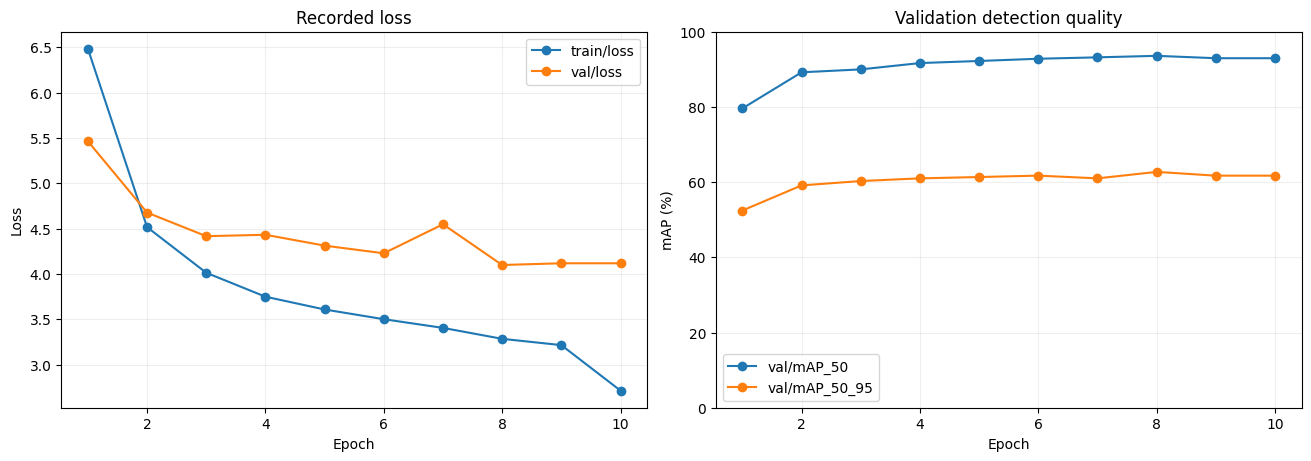

,status,stage,stop_reason,optimizer_updates,epoch_counter_including_partial,cuda_parameter_device,checkpoint,latest_resume,precision,elapsed_seconds,worker_exit_code
0,finished,full-training,time budget,2241,10,cuda:0,/content/drive/MyDrive/ICT304/FridgeChef_RFDET...,/content/drive/MyDrive/ICT304/FridgeChef_RFDET...,16-mixed,3066.163131,0


In [ ]:
# Read saved history without starting another training run.
history_root = SELECTED_CHECKPOINT.parent if SELECTED_CHECKPOINT else RUN_DIR / "native"
history_path = history_root / "metrics.csv"
if history_path.is_file():
    history = pd.read_csv(history_path)
    history = history.dropna(subset=["epoch"]).groupby("epoch", as_index=False).last()
    history["epoch_display"] = history.epoch.astype(int) + 1
    display(history.tail(20))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
    for column in ["train/loss", "train/loss_epoch", "val/loss"]:
        if column in history:
            axes[0].plot(history.epoch_display, history[column], marker="o", label=column)
    for column in ["val/mAP_50", "val/mAP_50_95"]:
        if column in history:
            axes[1].plot(history.epoch_display, 100 * history[column], marker="o", label=column)
    axes[0].set(title="Recorded loss", xlabel="Epoch", ylabel="Loss")
    axes[1].set(title="Validation detection quality", xlabel="Epoch", ylabel="mAP (%)", ylim=(0, 100))
    for axis in axes:
        axis.grid(alpha=.2)
        if axis.lines:
            axis.legend()
    plt.show()
    plt.close(fig)
    state_path = history_root.parent / "state.json"
    if state_path.is_file():
        display(pd.DataFrame([json.loads(state_path.read_text())]))
    if SELECTED_CHECKPOINT is not None:
        archived_best = WEIGHTS_DIR / "best.pth"
        shutil.copy2(SELECTED_CHECKPOINT, archived_best)
        save_json(WEIGHTS_DIR / "checkpoint_identity.json", {"source": str(SELECTED_CHECKPOINT),
            "sha256": sha256_file(archived_best), "class_names": CLASS_NAMES,
            "dataset_identity": DATASET_ID, "run_state": json.loads(state_path.read_text()) if state_path.exists() else None,
            "resume_note": "Use the original run's native .ckpt for resume; this copy contains inference weights."})
else:
    print("No full-training history is available yet. No RF-DETR accuracy is claimed.")

## Validation and prediction exports
**IoU** measures overlap between predicted and labelled boxes. **mAP** summarizes detection quality across confidence thresholds. mAP50 uses IoU 0.50; mAP50–95 averages IoU 0.50 to 0.95.

Export every image, including empty predictions, with canonical classes and boxes in original pixels. AP uses low-confidence candidates. Collapsed boxes are counted per image and removed; other invalid predictions raise an error.

In [ ]:
def evaluation_ready():
    """Return whether a selected full-model checkpoint is available for evaluation."""
    return (model is not None and SELECTED_CHECKPOINT is not None
            and CONFIG['mode'] in {'full-training', 'resume', 'evaluate'})


def comparison_protocol():
    """Return the common scoring rules recorded with every export."""
    return {'version': 'FridgeChef-shared-COCO-v1', 'class_names': list(CLASS_NAMES),
            'box_format': 'xyxy_original_image_pixels',
            'candidate_floor': float(CONFIG['prediction_floor']),
            'candidate_rule': 'confidence strictly greater than floor',
            'maximum_detections': int(CONFIG['max_detections']),
            'ap_IoU_thresholds': np.linspace(.5, .95, 10).tolist(),
            'ap_recall_points': 101, 'ap_average': 'macro over supported classes',
            'detection_matching': 'confidence-ordered same-class one-to-one',
            'matching_IoU': float(CONFIG['match_iou']),
            'ingredient_matching': 'unique canonical classes per image; no IoU'}


def checkpoint_identity():
    """Return the selected checkpoint hash and verify the custom label vocabulary."""
    assert evaluation_ready(), 'A full-model checkpoint must be selected first.'
    assert list(model.class_names) == list(CLASS_NAMES)
    assert model.model_config.num_classes == len(CLASS_NAMES)
    assert model.model.postprocess.num_select == CONFIG['max_detections']
    assert next(model.model.model.parameters()).device.type == 'cuda', 'Evaluation requires CUDA.'
    return sha256_file(Path(SELECTED_CHECKPOINT))


def require_final_test_lock():
    """Read frozen validation settings and reject changed checkpoints or scoring rules."""
    assert evaluation_ready() and CONFIG['final_test_enabled'] and CONFIG['settings_frozen']
    assert CONFIG['mode'] == 'evaluate', 'Use evaluation mode for final testing.'
    assert not CONFIG['run_validation'], 'Final testing must not retune validation settings.'
    assert CONFIG['frozen_settings_path'], 'Provide the saved frozen validation settings file.'
    locked = json.loads(Path(CONFIG['frozen_settings_path']).read_text())
    assert locked['source'] == 'validation only'
    assert locked['checkpoint_sha256'] == checkpoint_identity()
    assert locked['dataset_identity'] == DATASET_ID
    assert locked['protocol'] == comparison_protocol()
    assert locked['resolution'] == int(model.model_config.resolution)
    return locked


In [ ]:
def canonical_predictions(result, width, height):
    """Convert one RF-DETR result to checked canonical labels and original-pixel boxes."""
    detections = []
    audit = {'background_removed': 0, 'clipped_boxes': 0, 'zero_area_removed': 0}
    assert len(result.class_id) == len(result.confidence) == len(result.xyxy)
    output_names = result.data.get('class_name')
    source_shapes = result.data.get('source_shape')
    if source_shapes is not None and len(result.class_id):
        assert np.array_equal(source_shapes, np.tile([height, width], (len(result.class_id), 1)))
    for index, (raw_id, score, raw_box) in enumerate(zip(result.class_id, result.confidence, result.xyxy)):
        assert np.isfinite(raw_id) and float(raw_id).is_integer()
        class_id = int(raw_id)
        assert np.isfinite(score) and 0 <= float(score) <= 1
        if class_id == len(CLASS_NAMES):
            audit['background_removed'] += 1
            continue
        # Custom RF-DETR predictions already use the dataset's zero-based class IDs.
        assert 0 <= class_id < len(CLASS_NAMES), 'Unexpected prediction category; do not shift IDs.'
        if output_names is not None:
            assert str(output_names[index]) == CLASS_NAMES[class_id]
        raw_box = np.asarray(raw_box, dtype=float)
        assert raw_box.shape == (4,) and np.isfinite(raw_box).all()
        # Allow collapsed boxes so the next check can count and remove them.
        assert raw_box[2] >= raw_box[0] and raw_box[3] >= raw_box[1]
        box = np.clip(raw_box, [0, 0, 0, 0], [width, height, width, height])
        audit['clipped_boxes'] += int(not np.array_equal(raw_box, box))
        if box[2] <= box[0] or box[3] <= box[1]:
            audit['zero_area_removed'] += 1
            continue
        detections.append({'class_id': class_id, 'class_name': CLASS_NAMES[class_id],
                           'confidence': float(score), 'bbox_xyxy': box.tolist()})
    assert len(detections) <= CONFIG['max_detections']
    return detections, audit


def export_split_predictions(split, folder):
    """Predict every image in one split and save one JSON record per image, including empty results."""
    assert evaluation_ready() and split in {'valid', 'test'}
    if split == 'test':
        require_final_test_lock()
    checkpoint_hash = checkpoint_identity()
    folder.mkdir(parents=True, exist_ok=True)
    records = []
    rows = eda_images[eda_images.split == split].sort_values('image_id')
    from tqdm.auto import tqdm
    for row in tqdm(list(rows.itertuples()), desc=f'{split} predictions', unit='image'):
        with Image.open(DATASET_ROOT / row.image_path) as source:
            width, height = source.size
        result = model.predict(str(DATASET_ROOT / row.image_path),
                               threshold=CONFIG['prediction_floor'], include_source_image=False)
        detections, audit = canonical_predictions(result, width, height)
        records.append({'schema_version': 1, 'image_id': str(row.image_id), 'split': split,
            'image_path': str(row.image_path), 'source_dataset': str(row.dataset_name),
            'width': width, 'height': height, 'model': 'RF-DETR Small',
            'checkpoint': str(SELECTED_CHECKPOINT), 'checkpoint_sha256': checkpoint_hash,
            'dataset_identity': DATASET_ID, 'detections': detections, 'box_audit': audit})
    assert len(records) == len(rows) and len({r['image_id'] for r in records}) == len(rows)
    # Save every image, including those without detections.
    with (folder / 'predictions.jsonl').open('w') as output:
        for record in records:
            output.write(json.dumps(record) + '\n')
    save_json(folder / 'prediction_protocol.json', {**comparison_protocol(),
        'resolution': int(model.model_config.resolution), 'images': len(records),
        'all_images_included': True, 'no_detections': [], 'checkpoint_sha256': checkpoint_hash})
    return records


In [ ]:
def truth_for_predictions(records):
    """Convert the prepared normalized labels into pixel boxes for the exported images."""
    grouped_boxes = {name: frame for name, frame in eda_boxes.groupby('image_id')}
    truth = {}
    for record in records:
        items = []
        for row in grouped_boxes.get(record['image_id'], eda_boxes.iloc[0:0]).itertuples():
            assert row.split == record['split']
            box = [(row.center_x-row.box_width/2)*record['width'],
                   (row.center_y-row.box_height/2)*record['height'],
                   (row.center_x+row.box_width/2)*record['width'],
                   (row.center_y+row.box_height/2)*record['height']]
            items.append({'class_id': int(row.class_id), 'class_name': CLASS_NAMES[int(row.class_id)],
                          'bbox_xyxy': box})
        truth[record['image_id']] = items
    return truth


def box_iou(first, second):
    """Return the intersection area divided by the union area of two pixel boxes."""
    overlap = max(0, min(first[2], second[2])-max(first[0], second[0]))
    overlap *= max(0, min(first[3], second[3])-max(first[1], second[1]))
    union = ((first[2]-first[0])*(first[3]-first[1])
             + (second[2]-second[0])*(second[3]-second[1])-overlap)
    return overlap / union if union > 0 else 0.0


def match_one_image(record, targets, threshold):
    """Return scored predictions, matched pairs, false predictions and missed target indices."""
    predictions = sorted([d for d in record['detections'] if d['confidence'] >= threshold],
                         key=lambda item: -item['confidence'])
    used_targets, matches, false_predictions = set(), [], []
    for prediction_index, prediction in enumerate(predictions):
        options = [(box_iou(prediction['bbox_xyxy'], target['bbox_xyxy']), target_index)
                   for target_index, target in enumerate(targets)
                   if target_index not in used_targets and target['class_id'] == prediction['class_id']]
        overlap, target_index = max(options, default=(0.0, -1))
        if target_index >= 0 and overlap >= CONFIG['match_iou']:
            matches.append((prediction_index, target_index))
            used_targets.add(target_index)
        else:
            false_predictions.append(prediction_index)
    missed_targets = [index for index in range(len(targets)) if index not in used_targets]
    return predictions, matches, false_predictions, missed_targets


In [ ]:
# Count each ingredient class once per image.
def ingredient_scores(records, truth, threshold):
    """Score deduplicated ingredient lists across all images at a fixed confidence threshold."""
    true_positive = false_positive = missed = correct_empty = 0
    for record in records:
        expected = {target['class_id'] for target in truth[record['image_id']]}
        predicted = {item['class_id'] for item in record['detections'] if item['confidence'] >= threshold}
        true_positive += len(expected & predicted)
        false_positive += len(predicted - expected)
        missed += len(expected - predicted)
        correct_empty += int(not expected and not predicted)
    precision = true_positive / max(1, true_positive + false_positive)
    recall = true_positive / max(1, true_positive + missed)
    return {'confidence': float(threshold), 'precision': precision, 'recall': recall,
            'F1': 2*precision*recall/(precision+recall) if precision+recall else 0.0,
            'true_positive_ingredients': true_positive, 'false_positive_ingredients': false_positive,
            'missed_ingredients': missed, 'correct_empty_lists': correct_empty, 'images': len(records)}


def detection_scores(records, truth, threshold):
    """Calculate per-class and pooled box precision and recall with one-to-one IoU matching."""
    counts = np.zeros((len(CLASS_NAMES), 3), dtype=int)
    for record in records:
        targets = truth[record['image_id']]
        predictions, matches, false_predictions, missed_targets = match_one_image(record, targets, threshold)
        for prediction_index, _ in matches:
            counts[predictions[prediction_index]['class_id'], 0] += 1
        for prediction_index in false_predictions:
            counts[predictions[prediction_index]['class_id'], 1] += 1
        for target_index in missed_targets:
            counts[targets[target_index]['class_id'], 2] += 1
    table = pd.DataFrame(counts, columns=['TP', 'FP', 'FN']).rename_axis('class_id').reset_index()
    table['precision'] = table.TP / (table.TP + table.FP).clip(lower=1)
    table['recall'] = table.TP / (table.TP + table.FN).replace(0, np.nan)
    tp, fp, fn = counts.sum(axis=0)
    summary = {'confidence': float(threshold), 'matching_IoU': float(CONFIG['match_iou']),
        'micro_precision': float(tp/max(1, tp+fp)), 'micro_recall': float(tp/max(1, tp+fn)),
        'true_positive_boxes': int(tp), 'false_positive_boxes': int(fp), 'missed_boxes': int(fn)}
    return summary, table


### Detection and ingredient scores
**Precision** measures how many predictions are correct. **Recall** measures how many labelled targets are found.

COCO evaluation calculates AP. Box precision and recall use the selected confidence and same-class IoU matching. Ingredient scores count each class once per image. Report sparse class support; AP is unavailable when a class has no labelled objects.

In [ ]:
# Calculate AP before applying the demonstration confidence threshold.
def score_average_precision(records, truth):
    """Return overall and per-class COCO AP, including images that have no predictions."""
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval
    from contextlib import redirect_stdout
    from io import StringIO
    categories = [{'id': i, 'name': name} for i, name in enumerate(CLASS_NAMES)]
    images, annotations, predictions = [], [], []
    for image_number, record in enumerate(records, 1):
        images.append({'id': image_number, 'width': record['width'], 'height': record['height']})
        for target in truth[record['image_id']]:
            x1, y1, x2, y2 = target['bbox_xyxy']
            annotations.append({'id': len(annotations)+1, 'image_id': image_number,
                'category_id': target['class_id'], 'bbox': [x1, y1, x2-x1, y2-y1],
                'area': (x2-x1)*(y2-y1), 'iscrowd': 0})
        for prediction in record['detections']:
            if prediction['confidence'] <= CONFIG['prediction_floor']:
                continue
            x1, y1, x2, y2 = prediction['bbox_xyxy']
            predictions.append({'id': len(predictions)+1, 'image_id': image_number,
                'category_id': prediction['class_id'], 'bbox': [x1, y1, x2-x1, y2-y1],
                'area': (x2-x1)*(y2-y1), 'iscrowd': 0, 'score': prediction['confidence']})
    # Building both objects explicitly also supports an entirely empty prediction list.
    with redirect_stdout(StringIO()):
        actual, detected = COCO(), COCO()
        actual.dataset = {'info': {}, 'images': images, 'categories': categories, 'annotations': annotations}
        detected.dataset = {'info': {}, 'images': images, 'categories': categories, 'annotations': predictions}
        actual.createIndex()
        detected.createIndex()
        evaluator = COCOeval(actual, detected, 'bbox')
        evaluator.params.imgIds = [image['id'] for image in images]
        evaluator.params.catIds = list(range(len(CLASS_NAMES)))
        evaluator.params.maxDets = [1, 10, CONFIG['max_detections']]
        evaluator.params.iouThrs = np.linspace(.5, .95, 10)
        evaluator.params.recThrs = np.linspace(0, 1, 101)
        evaluator.evaluate()
        evaluator.accumulate()
    grid = evaluator.eval['precision'][:, :, :, 0, -1]
    def available_mean(values):
        available = values[values >= 0]
        return float(available.mean()) if available.size else float('nan')
    per_class = pd.DataFrame([{'class_id': i, 'class_name': name,
        'AP50': available_mean(grid[0, :, i]), 'AP50_95': available_mean(grid[:, :, i])}
        for i, name in enumerate(CLASS_NAMES)])
    return {'mAP50': available_mean(grid[0]), 'mAP50_95': available_mean(grid)}, per_class


In [ ]:
def report_split_metrics(records, truth, threshold, folder):
    """Save AP, operating-point detection scores, ingredient scores and support tables."""
    assert records and len({record['image_id'] for record in records}) == len(records)
    splits = {record['split'] for record in records}
    assert len(splits) == 1
    split = next(iter(splits))
    assert all(record['dataset_identity'] == DATASET_ID for record in records)
    average_precision, per_class = score_average_precision(records, truth)
    detection_summary, detection_table = detection_scores(records, truth, threshold)
    ingredient_summary = ingredient_scores(records, truth, threshold)
    support = eda_frozen_support[eda_frozen_support.split == split].rename(columns={'export_class_id': 'class_id'})
    support_columns = ['class_id', 'images', 'objects', 'independent_dependency_groups', 'source_photographs', 'confirmed_scenes']
    per_class = per_class.merge(detection_table, on='class_id', validate='one_to_one')
    per_class = per_class.merge(support[support_columns], on='class_id', validate='one_to_one')
    per_class['support_note'] = np.where(per_class.objects == 0, 'no annotated support',
                                       np.where(per_class.images < 10, 'fewer than 10 images', ''))
    summary = {'split': split, 'images': len(records), **average_precision, **detection_summary,
        'checkpoint_sha256': records[0]['checkpoint_sha256'], 'dataset_identity': DATASET_ID,
        'protocol': comparison_protocol()}
    save_json(folder / 'detection_metrics.json', summary)
    save_json(folder / 'ingredient_metrics.json', ingredient_summary)
    per_class.to_csv(folder / 'per_class_metrics.csv', index=False)
    display(pd.DataFrame([{'split': split, 'images': len(records), **average_precision, **detection_summary}]))
    display(Markdown('**Deduplicated ingredient-list metrics:**'))
    display(pd.DataFrame([ingredient_summary]))
    with pd.option_context('display.max_rows', 50):
        display(per_class)
    return summary, per_class


In [ ]:
def draw_detection_boxes(axis, detections, colour, scores=False):
    """Draw original-pixel boxes with readable names and optional confidence scores."""
    from matplotlib.patches import Rectangle
    for item in detections:
        x1, y1, x2, y2 = item['bbox_xyxy']
        axis.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor=colour, linewidth=1.3))
        label = item['class_name'].replace('_', ' ')
        if scores:
            label += f" {item['confidence']:.2f}"
        axis.text(x1, max(0, y1-2), label, fontsize=7, color='white',
                  bbox={'facecolor': colour, 'alpha': .8, 'pad': 1})


def validation_error_examples(records, truth, threshold, folder):
    """Show validation examples selected by false-box and missed-box counts."""
    assert all(record['split'] == 'valid' for record in records)
    error_rows = []
    for record in records:
        _, matches, false_predictions, missed_targets = match_one_image(record, truth[record['image_id']], threshold)
        error_rows.append({'image_id': record['image_id'], 'matched_boxes': len(matches),
                           'false_boxes': len(false_predictions), 'missed_boxes': len(missed_targets)})
    errors = pd.DataFrame(error_rows)
    errors.to_csv(folder / 'validation_box_errors.csv', index=False)
    display(errors.sort_values(['missed_boxes', 'false_boxes'], ascending=False).head(10))
    lookup = {record['image_id']: record for record in records}
    selected = set()
    for error_type in ['false_boxes', 'missed_boxes']:
        candidates = errors[errors[error_type] > 0].sort_values([error_type, 'image_id'], ascending=[False, True])
        if candidates.empty:
            print('No validation example with', error_type.replace('_', ' '))
            continue
        image_id = candidates.iloc[0].image_id
        if image_id in selected:
            continue
        selected.add(image_id)
        record = lookup[image_id]
        with Image.open(DATASET_ROOT / record['image_path']) as source:
            photograph = source.convert('RGB')
        figure, axes = plt.subplots(1, 2, figsize=(15, 7), layout='constrained')
        for axis in axes:
            axis.imshow(photograph)
            axis.axis('off')
        draw_detection_boxes(axes[0], truth[image_id], 'forestgreen')
        draw_detection_boxes(axes[1], [d for d in record['detections'] if d['confidence'] >= threshold], 'darkorange', True)
        axes[0].set_title('Ground truth — validation')
        axes[1].set_title(f'Predictions — confidence ≥ {threshold:.2f}')
        figure.suptitle(error_type.replace('_', ' ') + ': ' + image_id, fontsize=10)
        figure.savefig(folder / (error_type + '.png'), dpi=140, bbox_inches='tight')
        plt.show()
        plt.close(figure)


In [ ]:
# Measure prediction time after warm-up, without drawing or export.
def inference_timing(folder, threshold):
    """Measure CUDA-synchronised end-to-end latency on a reproducible validation sample."""
    import time
    assert torch.cuda.is_available(), 'Timing requires the selected CUDA runtime.'
    rows = eda_images[eda_images.split == 'valid'].sort_values('image_id').head(20)
    paths = [DATASET_ROOT / path for path in rows.image_path]
    for index in range(3):
        model.predict(str(paths[index % len(paths)]), threshold=threshold, include_source_image=False)
    times = []
    for image_id, path in zip(rows.image_id, paths):
        torch.cuda.synchronize()
        started = time.perf_counter()
        model.predict(str(path), threshold=threshold, include_source_image=False)
        torch.cuda.synchronize()
        times.append({'image_id': image_id, 'milliseconds': 1000*(time.perf_counter()-started)})
    table = pd.DataFrame(times)
    table.to_csv(folder / 'inference_timing.csv', index=False)
    parameters = next(model.model.model.parameters())
    summary = {'median_ms': float(table.milliseconds.median()), 'p90_ms': float(table.milliseconds.quantile(.9)),
        'sample_images': len(table), 'warmup_images': 3, 'batch': 1, 'threshold': float(threshold),
        'device': str(parameters.device), 'GPU': torch.cuda.get_device_name(), 'weight_dtype': str(parameters.dtype),
        'resolution': int(model.model_config.resolution), 'synchronization': 'CUDA before and after each call',
        'includes': 'file reading, preprocessing, forward pass and postprocessing',
        'excludes': 'model loading, drawing and export'}
    save_json(folder / 'inference_timing_summary.json', summary)
    display(pd.DataFrame([summary]))
    return summary


### Validate and choose confidence
Evaluate the selected full-training checkpoint on validation images. Choose the confidence threshold with the best ingredient **F1**, which balances precision and recall. Ties favour the higher threshold.

Save the checkpoint, dataset and settings for final testing. Prediction progress counts images, not training epochs. These evaluation cells do not retrain the model.

In [ ]:
# Choose the display confidence from validation results only.
VALIDATION_RECORDS = None
VALIDATION_THRESHOLD = None
FROZEN_VALIDATION_PATH = None
if evaluation_ready() and CONFIG['run_validation'] and not CONFIG['final_test_enabled']:
    validation_folder = EVAL_DIR / 'validation'
    VALIDATION_RECORDS = export_split_predictions('valid', validation_folder)
    validation_truth = truth_for_predictions(VALIDATION_RECORDS)
    threshold_table = pd.DataFrame([ingredient_scores(VALIDATION_RECORDS, validation_truth, threshold)
                                    for threshold in CONFIG['threshold_candidates']])
    threshold_table.to_csv(validation_folder / 'validation_thresholds.csv', index=False)
    display(threshold_table)
    selected = threshold_table.sort_values(['F1', 'confidence'], ascending=[False, False]).iloc[0]
    VALIDATION_THRESHOLD = float(selected.confidence)
    validation_metrics, validation_per_class = report_split_metrics(
        VALIDATION_RECORDS, validation_truth, VALIDATION_THRESHOLD, validation_folder)
    validation_error_examples(VALIDATION_RECORDS, validation_truth, VALIDATION_THRESHOLD, validation_folder)
    inference_timing(validation_folder, VALIDATION_THRESHOLD)
    frozen = {'source': 'validation only', 'threshold': VALIDATION_THRESHOLD,
        'selection_rule': 'maximum validation ingredient-list F1; ties use higher confidence',
        'checkpoint_sha256': checkpoint_identity(), 'checkpoint': str(SELECTED_CHECKPOINT),
        'dataset_identity': DATASET_ID, 'resolution': int(model.model_config.resolution),
        'protocol': comparison_protocol()}
    FROZEN_VALIDATION_PATH = validation_folder / 'frozen_validation_settings.json'
    save_json(FROZEN_VALIDATION_PATH, frozen)
    print('Selected validation confidence:', VALIDATION_THRESHOLD)
    print('Frozen settings for a later final test:', FROZEN_VALIDATION_PATH)
else:
    print('Validation skipped. Select a full-model checkpoint and enable validation; smoke checkpoints are excluded.')


Validation skipped. Select a full-model checkpoint and enable validation; smoke checkpoints are excluded.


### Class confusions
Rows show labelled classes; columns show predicted classes. Boxes are paired by overlap regardless of class. Off-diagonal entries show wrong labels; the final row and column show false detections and misses. This diagnostic is separate from AP scoring.

In [ ]:
# Show wrong labels separately from missed and extra boxes.
if VALIDATION_RECORDS is not None:
    background = len(CLASS_NAMES)
    confusion = np.zeros((background + 1, background + 1), dtype=int)
    for record in VALIDATION_RECORDS:
        targets = validation_truth[record["image_id"]]
        predictions = sorted([item for item in record["detections"] if item["confidence"] >= VALIDATION_THRESHOLD],
                             key=lambda item: -item["confidence"])
        matched_targets = set()
        for prediction in predictions:
            overlaps = [(box_iou(prediction["bbox_xyxy"], target["bbox_xyxy"]), index)
                        for index, target in enumerate(targets) if index not in matched_targets]
            overlap, index = max(overlaps, default=(0.0, -1))
            if index >= 0 and overlap >= CONFIG["match_iou"]:
                confusion[targets[index]["class_id"], prediction["class_id"]] += 1
                matched_targets.add(index)
            else:
                confusion[background, prediction["class_id"]] += 1
        for index, target in enumerate(targets):
            if index not in matched_targets:
                confusion[target["class_id"], background] += 1
    labels = [name.replace("_", " ") for name in CLASS_NAMES] + ["unmatched / missed"]
    confusion_table = pd.DataFrame(confusion, index=labels, columns=labels)
    confusion_table.to_csv(EVAL_DIR / "validation/confusion_counts.csv")
    row_totals = confusion.sum(axis=1, keepdims=True)
    normalized_confusion = np.divide(confusion, row_totals, out=np.zeros_like(confusion, dtype=float), where=row_totals > 0)
    fig, axis = plt.subplots(figsize=(16, 14), layout="constrained")
    plot = axis.imshow(normalized_confusion, vmin=0, vmax=1, cmap="Blues")
    axis.set_xticks(range(len(labels)), labels, rotation=90, fontsize=9)
    axis.set_yticks(range(len(labels)), labels, fontsize=9)
    axis.set(title="Validation class confusions — row-normalized", xlabel="Predicted class", ylabel="Labelled class")
    fig.colorbar(plot, ax=axis, label="Fraction within row", shrink=.8)
    fig.savefig(EVAL_DIR / "validation/confusion_matrix.png", dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)
else:
    print("Confusion matrix waits for real validation predictions.")

Confusion matrix waits for real validation predictions.


## Final test evaluation
The submission already uses its validation-selected checkpoint and settings:

- `mode="evaluate"` and `full_checkpoint` set to the chosen native best weights.
- `run_validation=False`.
- `frozen_settings_path` set to the saved validation settings file.
- `settings_frozen=True` and `final_test_enabled=True`.

Keep all other inference settings fixed. Evaluate the 97 test images without retuning. Compare models using the same images and scoring rules.

In [ ]:
# Run the final test only after its saved settings pass the checks.
if CONFIG['final_test_enabled']:
    assert evaluation_ready(), 'Select a full-model checkpoint in evaluation mode first.'
    frozen_test_settings = require_final_test_lock()
    test_folder = EVAL_DIR / 'final_test'
    test_records = export_split_predictions('test', test_folder)
    test_truth = truth_for_predictions(test_records)
    test_metrics, test_per_class = report_split_metrics(
        test_records, test_truth, float(frozen_test_settings['threshold']), test_folder)
    save_json(test_folder / 'frozen_settings_used.json', frozen_test_settings)
else:
    print('Final testing is disabled. Test images, predictions and performance are reserved for the fixed final evaluation.')


test predictions:   0%|          | 0/97 [00:00<?, ?image/s]

[2026-10-03 00:46:36] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


,split,images,mAP50,mAP50_95,confidence,matching_IoU,micro_precision,micro_recall,true_positive_boxes,false_positive_boxes,missed_boxes
0,test,97,0.940216,0.621812,0.3,0.5,0.894344,0.932147,838,99,61


**Deduplicated ingredient-list metrics:**

,confidence,precision,recall,F1,true_positive_ingredients,false_positive_ingredients,missed_ingredients,correct_empty_lists,images
0,0.3,0.966667,0.972903,0.969775,754,26,21,10,97


,class_id,class_name,AP50,AP50_95,TP,FP,FN,precision,recall,images,objects,independent_dependency_groups,source_photographs,confirmed_scenes,support_note
0,0,apple,0.872914,0.520415,57,12,4,0.826087,0.934426,35,61,35,35,35,
1,1,banana,1.000000,0.675044,20,0,0,1.000000,1.000000,17,20,17,17,17,
2,2,beef,1.000000,0.281430,30,3,0,0.909091,1.000000,30,30,30,30,30,
3,3,blueberries,1.000000,0.552490,23,0,0,1.000000,1.000000,23,23,23,23,23,
4,4,bread,0.939193,0.627320,34,11,5,0.755556,0.871795,36,39,36,36,36,
5,5,butter_or_spread,1.000000,0.769217,12,0,0,1.000000,1.000000,12,12,12,12,12,
6,6,carrot,0.839750,0.482447,29,2,4,0.935484,0.878788,25,33,25,25,25,
7,7,cheese,1.000000,0.732071,29,0,0,1.000000,1.000000,29,29,29,29,29,
8,8,chicken,1.000000,0.582407,32,0,0,1.000000,1.000000,32,32,32,32,32,
9,9,chicken_breast,0.966761,0.393714,22,3,1,0.880000,0.956522,23,23,23,23,23,


## Photograph demonstration
Set `demo_image` to a photograph path, or use the default validation image. Show the input, boxes, confidence scores and a deduplicated ingredient list. No detections produce an empty list.

Detection does not establish quantity, freshness or expiry.

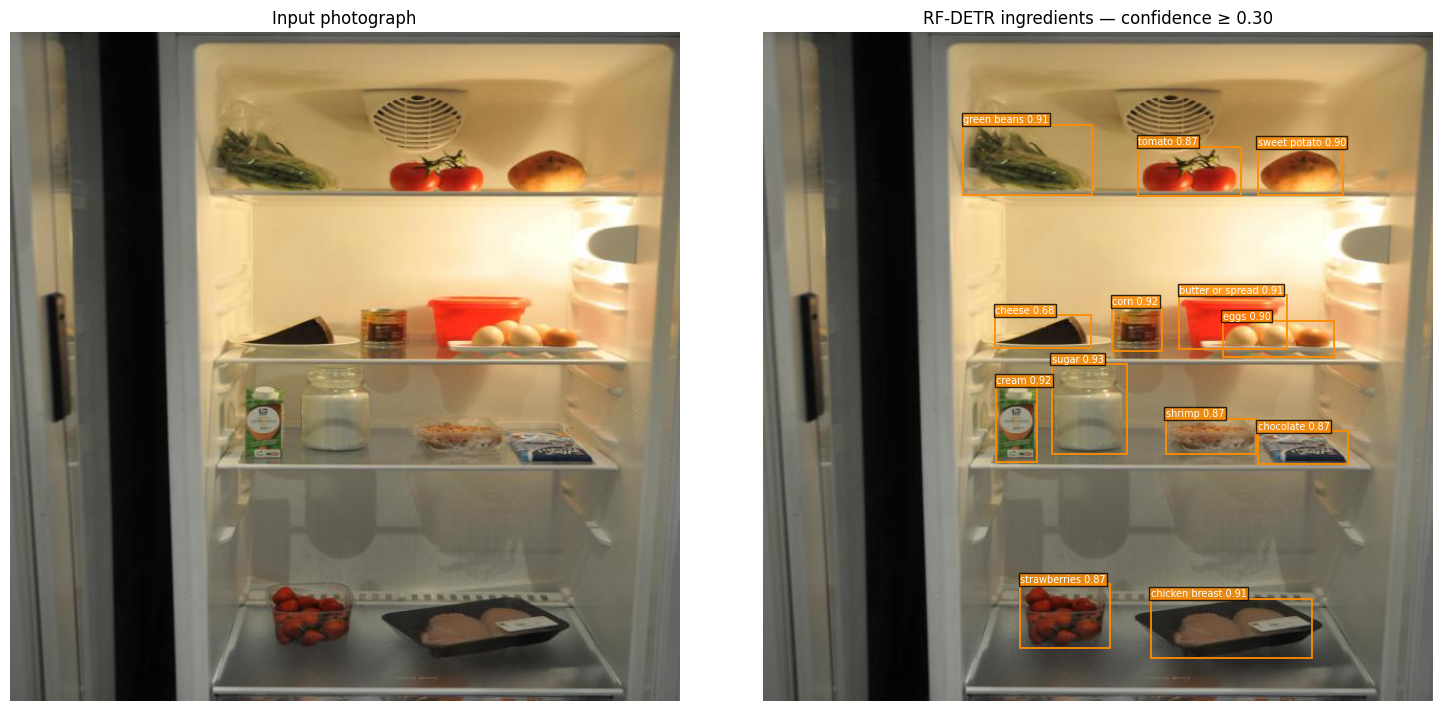

,class_id,class_name,display_name,confidence
0,5,butter_or_spread,butter or spread,0.908440
1,7,cheese,cheese,0.681000
2,9,chicken_breast,chicken breast,0.909552
3,10,chocolate,chocolate,0.865708
4,11,corn,corn,0.916510
5,12,eggs,eggs,0.896647
6,15,green_beans,green beans,0.914285
7,18,cream,cream,0.921386
8,24,shrimp,shrimp,0.871885
9,26,strawberries,strawberries,0.868025


{
  "image": "/content/dataset/Fridge_Combined_YOLO/valid/images/ai__021bf566500b9e572948.jpg",
  "threshold": 0.3,
  "ingredients": [
    {
      "class_id": 5,
      "class_name": "butter_or_spread",
      "display_name": "butter or spread",
      "confidence": 0.908440113067627
    },
    {
      "class_id": 7,
      "class_name": "cheese",
      "display_name": "cheese",
      "confidence": 0.6809999942779541
    },
    {
      "class_id": 9,
      "class_name": "chicken_breast",
      "display_name": "chicken breast",
      "confidence": 0.9095515012741089
    },
    {
      "class_id": 10,
      "class_name": "chocolate",
      "display_name": "chocolate",
      "confidence": 0.8657077550888062
    },
    {
      "class_id": 11,
      "class_name": "corn",
      "display_name": "corn",
      "confidence": 0.9165096879005432
    },
    {
      "class_id": 12,
      "class_name": "eggs",
      "display_name": "eggs",
      "confidence": 0.8966473937034607
    },
    {
      "class_

In [ ]:
# Combine repeated detections into one entry per ingredient.
def ingredient_list(detections, threshold):
    """Return one entry per detected ingredient, retaining its strongest confidence."""
    strongest = {}
    for item in detections:
        if item['confidence'] >= threshold:
            class_id = item['class_id']
            strongest[class_id] = max(strongest.get(class_id, 0.0), item['confidence'])
    return [{'class_id': class_id, 'class_name': CLASS_NAMES[class_id],
             'display_name': CLASS_NAMES[class_id].replace('_', ' '), 'confidence': strongest[class_id]}
            for class_id in sorted(strongest)]


if evaluation_ready():
    demo_threshold = VALIDATION_THRESHOLD
    if demo_threshold is None and CONFIG['frozen_settings_path']:
        demo_settings = json.loads(Path(CONFIG['frozen_settings_path']).read_text())
        assert demo_settings['checkpoint_sha256'] == checkpoint_identity()
        assert demo_settings['dataset_identity'] == DATASET_ID
        assert demo_settings['protocol'] == comparison_protocol()
        assert demo_settings['resolution'] == int(model.model_config.resolution)
        demo_threshold = float(demo_settings['threshold'])
    if demo_threshold is None:
        print('Run validation or provide its frozen settings before displaying the ingredient demonstration.')
    else:
        demo_path = Path(CONFIG['demo_image']) if CONFIG['demo_image'] else DATASET_ROOT / eda_images[
            eda_images.split == 'valid'].sort_values('image_id').iloc[0].image_path
        test_paths = {(DATASET_ROOT / path).resolve() for path in eda_images[eda_images.split == 'test'].image_path}
        assert demo_path.resolve() not in test_paths, 'Choose a supplied photograph or validation image for the demo.'
        with Image.open(demo_path) as source:
            demo_photo = source.convert('RGB')
        demo_result = model.predict(demo_photo, threshold=demo_threshold, include_source_image=False)
        demo_detections, demo_audit = canonical_predictions(demo_result, *demo_photo.size)
        figure, axes = plt.subplots(1, 2, figsize=(15, 7), layout='constrained')
        for axis in axes:
            axis.imshow(demo_photo)
            axis.axis('off')
        axes[0].set_title('Input photograph')
        axes[1].set_title(f'RF-DETR ingredients — confidence ≥ {demo_threshold:.2f}')
        draw_detection_boxes(axes[1], demo_detections, 'darkorange', True)
        plt.show()
        plt.close(figure)
        demo_ingredients = ingredient_list(demo_detections, demo_threshold)
        display(pd.DataFrame(demo_ingredients, columns=['class_id', 'class_name', 'display_name', 'confidence']))
        print(json.dumps({'image': str(demo_path), 'threshold': demo_threshold, 'ingredients': demo_ingredients}, indent=2))
        if not demo_ingredients:
            print('No supported ingredients were detected at the selected confidence threshold.')
else:
    print('Photograph demonstration skipped until a full-model checkpoint is selected.')


## Results and limitations
Report the saved metrics, per-class support, training duration and measured inference time. Rare classes and related image variants limit conclusions. Compare models on the same split and evaluator.


### References
- Roboflow: [training](https://rfdetr.roboflow.com/latest/learn/train/), [customization](https://rfdetr.roboflow.com/latest/learn/train/customization/), [parameters](https://rfdetr.roboflow.com/latest/learn/train/training-parameters/) and [augmentation](https://rfdetr.roboflow.com/latest/learn/train/augmentations/).
- Lightning: [training time limits](https://lightning.ai/docs/pytorch/stable/common/trainer.html#max-time).
- Google: [Colab resource limits](https://research.google.com/colaboratory/faq.html).
- COCO: [detection evaluator](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py).
- Project sources: dataset README, class registry, split support, provenance, attribution and the YOLO11s notebook.